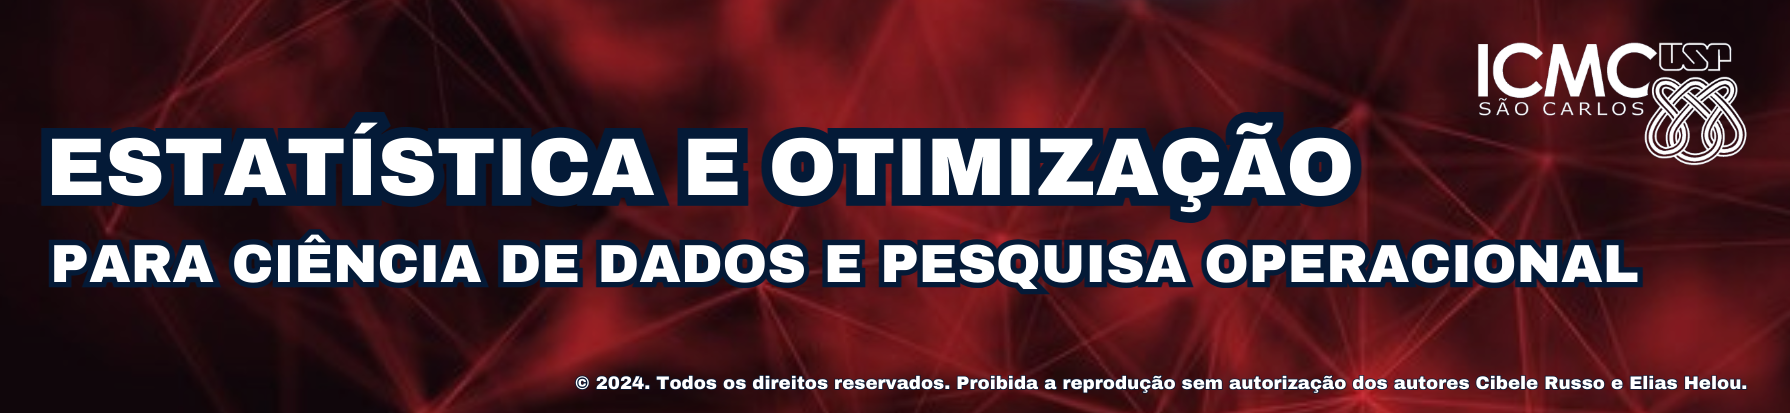

# Introdução à Modelagem estatística e preditiva para dados de séries temporais


por **Cibele Russo**

**ICMC/USP - São Carlos SP**

**Métodos Estatísticos Aplicados - 20/09/2025**


#### Resumo:
Esta aula discute brevemente aspectos de modelagem estatística e preditiva para dados de séries temporais.

Conteúdo: 
- Definição e visualização de séries temporais
- Tendência e Sazonalidade
- Autocorrelação e autocorrelação parcial
- Métodos de Holt-Winters
- Outros modelos: Theta, ARIMA
- Métricas de desempenho de modelos para séries temporais




**Referências:**

1. **Morettin, P.A.; Toloi, C.M.C. Análise de Séries Temporais - Modelos lineares univariados. Blucher, 2018.**
2. Eric D. Kolaczyk, Gábor Csárdi. Statistical Analysis of Network Data with R, Springer. 2014.
3. Paul S.P. Cowpertwait, Andrew V. Metcalfe. Introductory Time Series with R, Springer. 2009.
4. Louzada-Neto, F. ; Mazucheli, J. ; Achcar, J.A. . Análise de Sobrevivência e Confiabilidade. Lima, Peru: Instituto de Matematicas y Ciencias Afines, IMCA, 2002.
5. Colosimo, E. A. ; Giolo, S. R. Análise de Sobrevivência Aplicada. Blucher, 2006.
6. **Hyndman, R. ; Athanasopoulos, G. Forecasting: Principles and Practice. OTexts, 2018. Disponível em https://otexts.com/fpp3/**
7. Ehlers, R.S. Análise de Séries Temporais. ICMC USP. 2009.

# Séries temporais

### O que é uma série temporal?

**<span style="color:darkred">Uma série temporal é qualquer conjunto de observações ordenadas no tempo.</span>**

**Exemplos**

- valores diários de poluição na cidade de São Paulo

- número de óbitos diários registrados por COVID-19 no Brasil

- índices diários da Bovespa

- registro de marés no porto de Santos


**Objetivos**

São objetivos gerais dos estudos de séries temporais:

- **Identificar** padrões como tendência, sazonalidade, observações discrepantes (outliers);

- Usar a variação passada de uma série para **predizer** valores futuros. Embora não seja possível prever exatamente os valores futuros, podemos predizer um comportamento aproximado das próximas observações;

- **Entender** a variação conjunta de duas séries, e utilizar uma série para explicar a variação em outra série.

#### Para uma série temporal, observações vizinhas estão **correlacionadas**. Se em modelos de regressão a ordem das observações não importa, em modelos de séries temporais a ordem dos dados é crucial (Ehlers, 2009).

Algumas características são particulares a esse tipo de dados, por exemplo:

- Observações correlacionadas são mais difíceis de analisar e requerem técnicas específicas.

- Precisamos levar em conta a ordem temporal das observações.

- Fatores complicadores como presenca de tendências e variação sazonal ou cíclica podem ser difíceis de estimar ou remover.

- A seleção de modelos pode ser bastante complicada, e as ferramentas podem ser de difícil interpretação.

- É mais difıcil de lidar com observações perdidas e dados discrepantes devido à natureza sequencial.


## Motivação - Séries Temporais

### Exemplo: Dados de COVID-19 no estado de SP

Fonte dos dados originais: Brasil.IO: boletins epidemiológicos da COVID-19 por município por dia, disponível em: [https://brasil.io/datasets/](https://brasil.io/datasets/) (acesso em 08/03/2021,
utilizados dados utilizados de 26/2 a 31/12/2020). A partir dos dados originais, diversas bases de dados com registros de casos e óbitos por cidades brasileiras foram obtidas e serão disponibilizadas para estudo.

In [2]:
# Carrega as bibliotecas

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

import warnings
warnings.filterwarnings("ignore")


In [2]:
# Leitura dos dados

url = 'https://raw.githubusercontent.com/cibelerusso/Aprendizado-Dinamico/main/Data/covidSP.csv'

covidSP = pd.read_csv(url, parse_dates=True, index_col=0)
covidSP.head()

,confirmed,deaths
date,,
2020-02-26,0,0
2020-02-27,0,0
2020-02-28,1,0
2020-02-29,0,0
2020-03-01,0,0


In [3]:
covidSP.tail()

,confirmed,deaths
date,,
2020-12-26,1253,13
2020-12-27,2836,55
2020-12-28,1576,39
2020-12-29,12477,293
2020-12-30,11849,282


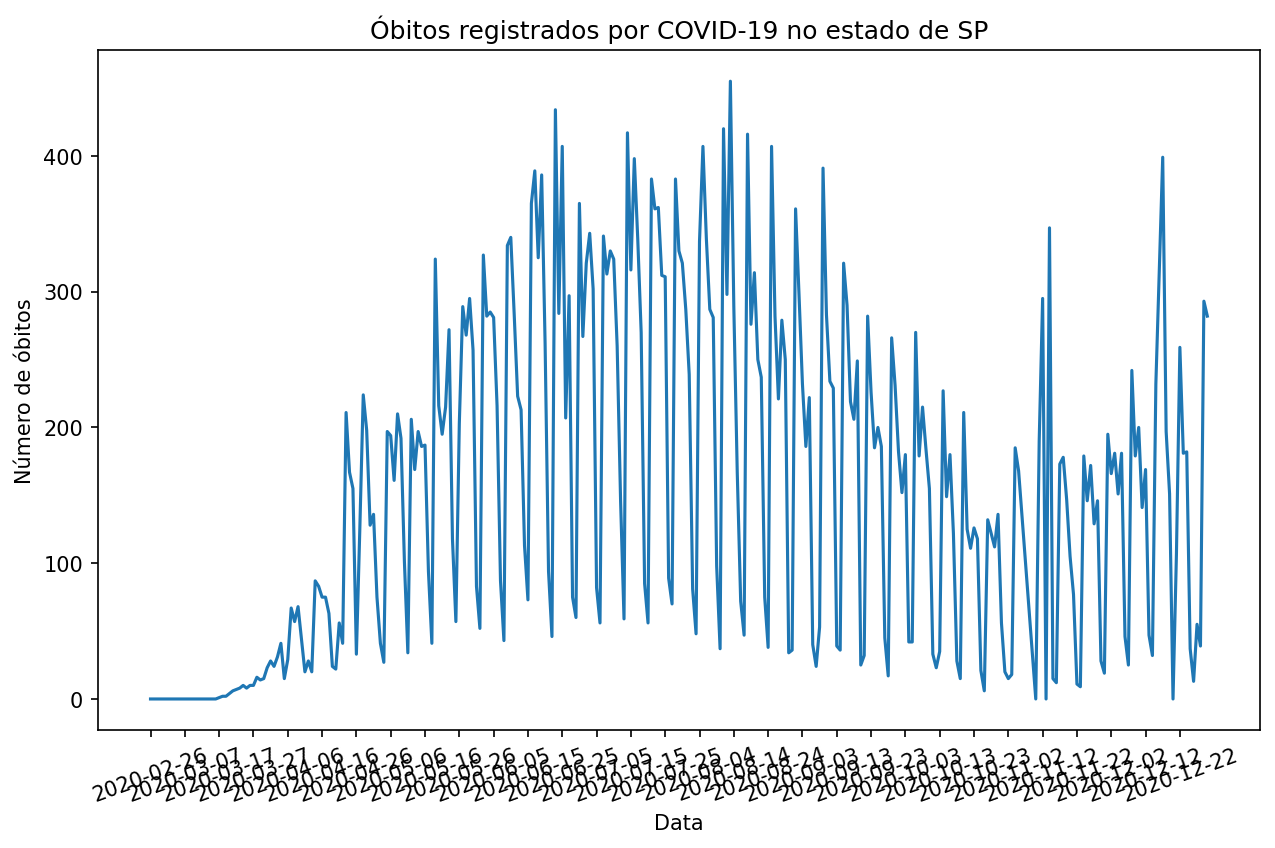

In [4]:
# COVID - Considere agora os dados de mortes diárias

y = covidSP['deaths']
x = covidSP.index

plt.rcParams['figure.figsize'] = [10,6]
plt.rcParams['figure.dpi'] = 150

plt.rc('font', size=10) # Altera o tamanho da fonte
plt.plot(x,y,label="Real data") # Plota os dados

plt.xticks(np.arange(x.min(),x.max(),10, dtype='datetime64[D]'),rotation=20)
plt.title("Óbitos registrados por COVID-19 no estado de %s" % 'SP')
plt.xlabel("Data")
plt.ylabel("Número de óbitos")
plt.ylim()
plt.show()


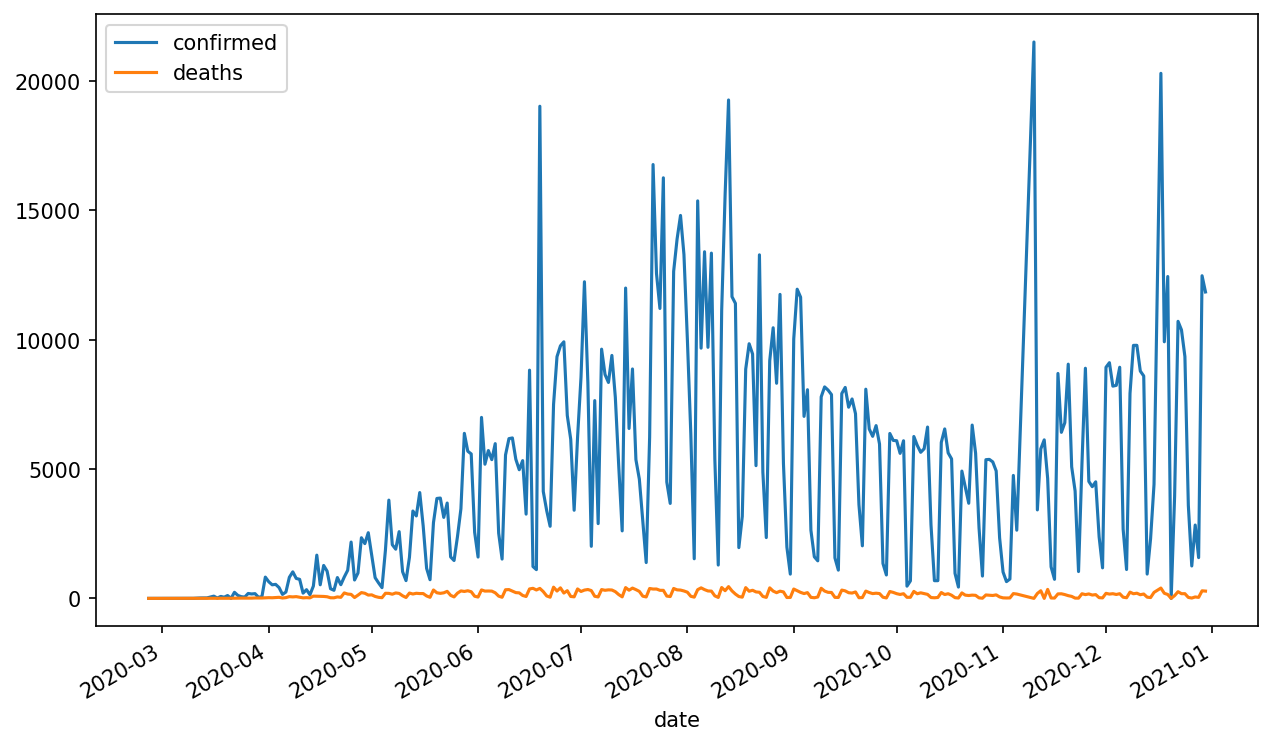

In [5]:
covidSP.plot();

**Exercícios**

1. Mesmo antes das definições formais, o que você entende por **tendência** e **sazonalidade** dos dados nesse caso?

2. Por que elas ocorrem?

### Motivação - Tendência e Sazonalidade

Considere o problema de decompor a série de mortes em **tendência, sazonalidade e resíduos (ruído)**. São conceitos que veremos adiante, mas usamos este problema para motivar o estudo de séries temporais.

In [6]:
# Instale o pacote statsmodels se necessário
#!pip show statsmodels

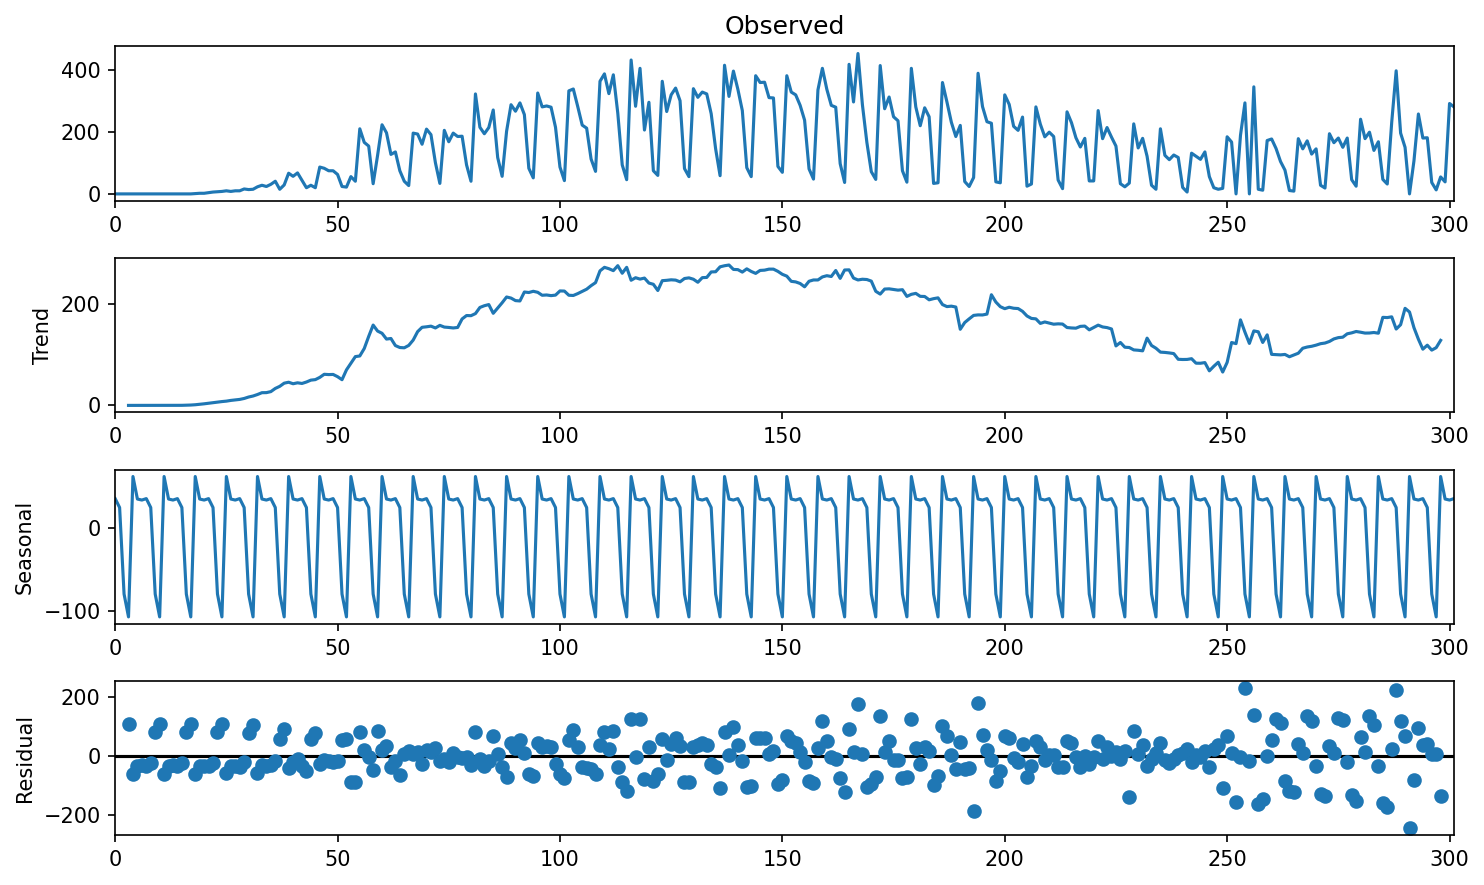

In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose
from matplotlib import pyplot

# y aqui são as mortes em SP

mortes = np.array(y)

result = seasonal_decompose(mortes, model='additive', period=7)
result.plot()

pyplot.show()

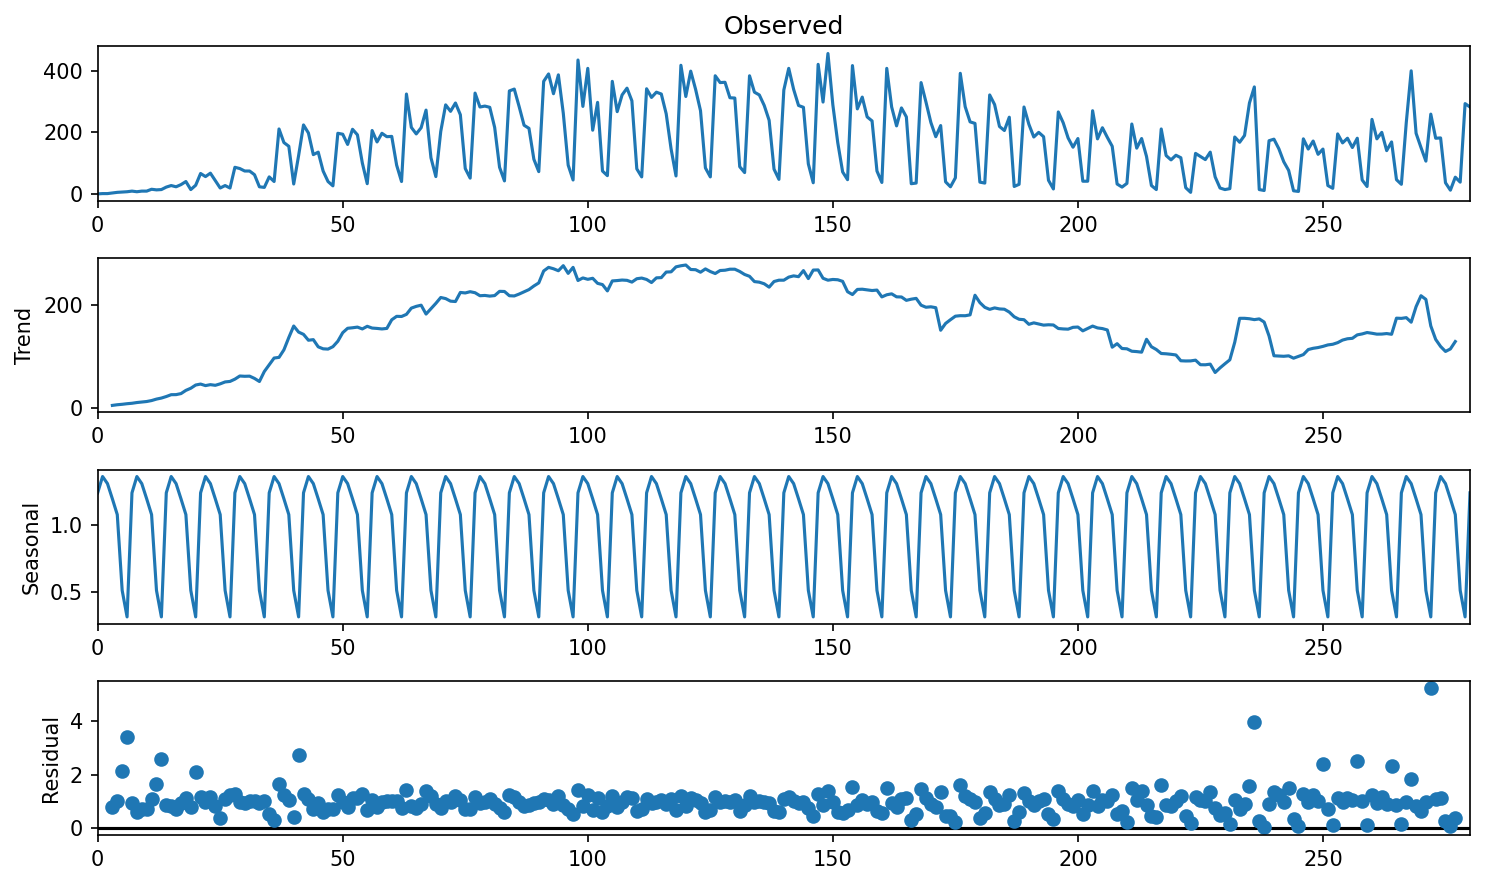

In [8]:
mortes = np.array(y)
mortes_pos = mortes[mortes>0]

result = seasonal_decompose(mortes_pos, model='multiplicative', period=7)
result.plot()

pyplot.show()

In [9]:
covidSP.head()

,confirmed,deaths
date,,
2020-02-26,0,0
2020-02-27,0,0
2020-02-28,1,0
2020-02-29,0,0
2020-03-01,0,0


### Obs: Lidando com datas

In [10]:
covidSP.index

DatetimeIndex(['2020-02-26', '2020-02-27', '2020-02-28', '2020-02-29',
               '2020-03-01', '2020-03-02', '2020-03-03', '2020-03-04',
               '2020-03-05', '2020-03-06',
               ...
               '2020-12-21', '2020-12-22', '2020-12-23', '2020-12-24',
               '2020-12-25', '2020-12-26', '2020-12-27', '2020-12-28',
               '2020-12-29', '2020-12-30'],
              dtype='datetime64[ns]', name='date', length=302, freq=None)

**Caso o índice não seja do tipo DatetimeIndex, algumas alternativas podem ser utilizadas:**


In [11]:
idx = pd.date_range('25/2/2020', periods=7, freq='D')
idx

DatetimeIndex(['2020-02-25', '2020-02-26', '2020-02-27', '2020-02-28',
               '2020-02-29', '2020-03-01', '2020-03-02'],
              dtype='datetime64[ns]', freq='D')

In [12]:
idx = pd.date_range('25/02/2020', periods=7, freq='M')
idx

DatetimeIndex(['2020-02-29', '2020-03-31', '2020-04-30', '2020-05-31',
               '2020-06-30', '2020-07-31', '2020-08-31'],
              dtype='datetime64[ns]', freq='ME')

In [13]:
idx = pd.to_datetime(['Feb 02, 2020', '2/25/2020', '25-Feb-2020', None], dayfirst=False, format='mixed')
print(idx)

DatetimeIndex(['2020-02-02', '2020-02-25', '2020-02-25', 'NaT'], dtype='datetime64[ns]', freq=None)


# Conceitos básicos

## Processos estocásticos

Os modelos utilizados para descrever séries temporais são processos estocásticos. Em geral, assume-se que uma **série temporal observada é uma realização de um processo estocástico adjacente**.


**Definição**

Seja $T$ um conjunto arbitrário. Um _processo estocástico_ é uma família $Z = \{Z(t), t\in T\}$ tal que, para cada $t\in T$, $Z(t)$ é uma variável aleatória.


Um processo estocástico pode ser visto como uma família de variáveis aleatórias. Por outro lado, uma realização ou trajetória do processo estocástico pode ser visto como uma **série temporal**.



O **espaço de estados** de um processo estocástico é o conjunto de todos os possíveis valores que as variáveis aleatórias $Z(t)$ podem assumir.

Características estatísticas:

- Média: $\mu(t) = E(Z(t))$

- Variância: $\sigma^2(t) = Var(Z(t))$

- Autocovariância: $\gamma(t_1,t_2) = E[Z(t_1)-\mu(t_1)][Z(t_2)-\mu(t_2)]$



### Séries Temporais


Considere uma série temporal $Z(t_1),Z(t_2),\ldots,Z(t_n)$ observada nos instantes $t_1,\ldots,t_n$, ou seja, uma realização ou trajetória de um processo estocástico. Temos interesse em

- **Investigar** o mecanismo gerador da série

- **Fazer previsões** para valores futuros da série

- **Descrever** o comportamento da série

- **Procurar periodicidades** relevantes nos dados

As séries temporais podem ser **contínuas** ou **discretas**, **univariadas** ou **multivariadas**.


# Tendência e Sazonalidade



Considere as observações $\{Z_t, t=1,\ldots,N\}$ de uma série temporal.

Podemos escrever um modelo de decomposição de $Z_t$ como uma soma de três componentes não-observáveis:

$$Z_t = T_t + S_t + a_t$$

em que

- $T_t$ representa uma componente de **tendência**

- $S_t$ representa uma componente de **sazonalidade**

- $a_t$ é uma **componente aleatória** (resíduos ou ruído), com média 0 e variância $\sigma^2_a$ .

Se $\{a_t\}$ for um ruído branco, então $Cov(a_t,a_s) = 0$ com $s\neq t$, mas podemos eventualmente relaxar essa suposição supondo $\{a_t\}$ um processo estacionário. Segue-se que, em geral, $\{Z_t\}$ é uma série não-estacionária.

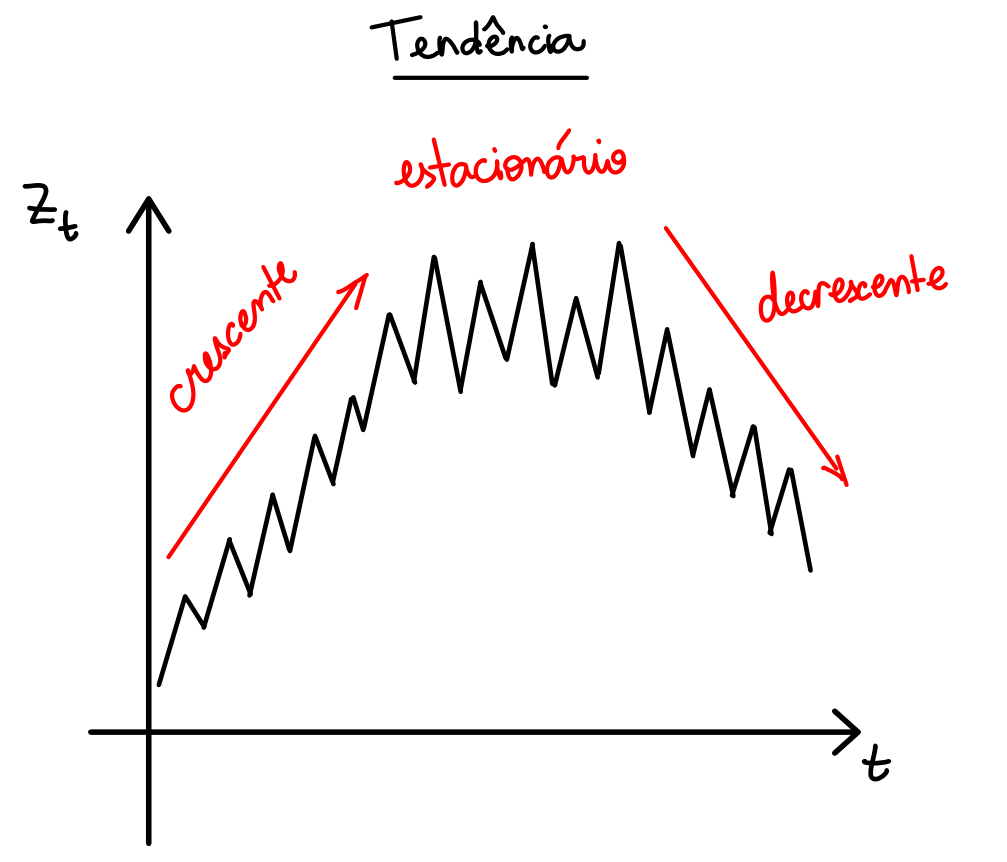

## Tendência

Suponha inicialmente que a componente sazonal $S_t$ não esteja presente. Um modelo inicial é

$$Z_t = T_t + a_t$$

em que $a_t$ é um ruído branco, com variância $\sigma^2_a$.

Queremos estimar $T_t$. Para isso, considere algumas possibilidades:

i. ajustar uma função no tempo, como um polinômio, uma exponencial ou outra função suave de $t$;

ii. suavizar (ou filtrar) os valores da série ao redor de um ponto, para estimar a tendência naquele ponto

iii. suavizar os valores da série através de sucessivos ajustes de retas de mínimos quadrados ponterados ('lowess')



Estimada a tendência, $\widehat{T}_t$, podemos obter a série ajustada para tendência ou livre de tendência

$$Y_t = Z_t - \widehat{T}_t$$

Para eliminar a tendência de uma série, também é possível considerar as diferenças. Normalmente para séries econômicas, a primeira diferença

$\Delta Z_t = Z_t - Z_{t-1}$ já é estacionária.



### Tendência polinomial

Suponha que

$$T_t = \beta_0+\beta_1t + \ldots +\beta_m t^m$$

onde o grau do polinômio $m$ é bem menor do que o número de observações N.

Pode-se utilizar o método de mínimos quadrados para estimar $\beta_0,\ldots,\beta_m$ e obter $\widehat{\beta}_0,\ldots,\widehat{\beta}_m$.

In [14]:
# Exemplo tendência polinomial - Carregando as bibliotecas

import pandas as pd
import numpy as np
import matplotlib.dates as mdates
import matplotlib.pyplot as plt


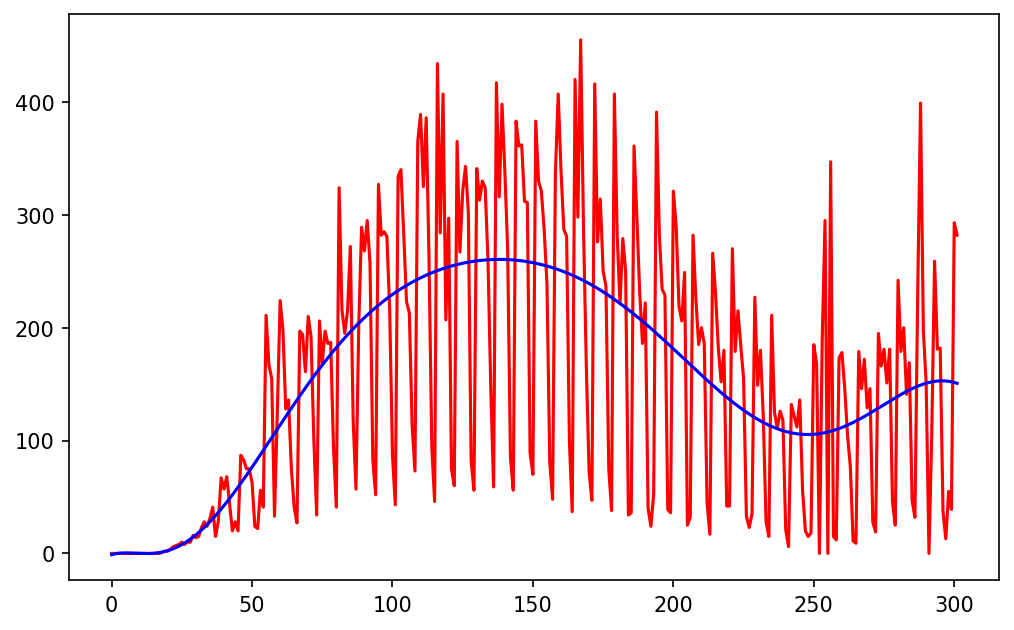

In [ ]:
#Leitura dos dados

url = 'https://raw.githubusercontent.com/cibelerusso/Aprendizado-Dinamico/main/Data/covidSP.csv'

# Leitura via github
covidSP = pd.read_csv(url,index_col='date',parse_dates=True)

# Aqui não trabalharemos com as datas mas sim com um índice inteiro das observações
x = np.array(range(len(covidSP.index)))
y = np.array(covidSP['deaths'])

polynomial = np.polyfit(x, y, 9)
p5 = np.poly1d(polynomial)

xx = np.linspace(x.min(), x.max(), len(y))

plt.rcParams['figure.figsize'] = [8,5]

plt.plot(x,y,label="Real data",color="red"); # Plota os dados
plt.plot(xx,p5(xx),label="Polinomio",color="blue"); # Polinômio

## Sazonalidade

Comportamento da série temporal tende a se repetir a cada s perı́odos de tempo.

Por exemplo, para dados de COVID-19, os picos em geral ocorrem às terças-feiras e aos fins de semana os registros diminuem, dada a sistemática das notificações.

**Tipos de Sazonalidade**

- **Aditiva**. A série apresenta flutuações sazonais mais ou menos constantes não importando o nı́vel global da série.

- **Multiplicativa**. O tamanho das flutuações sazonais varia dependendo do nı́vel global da série.


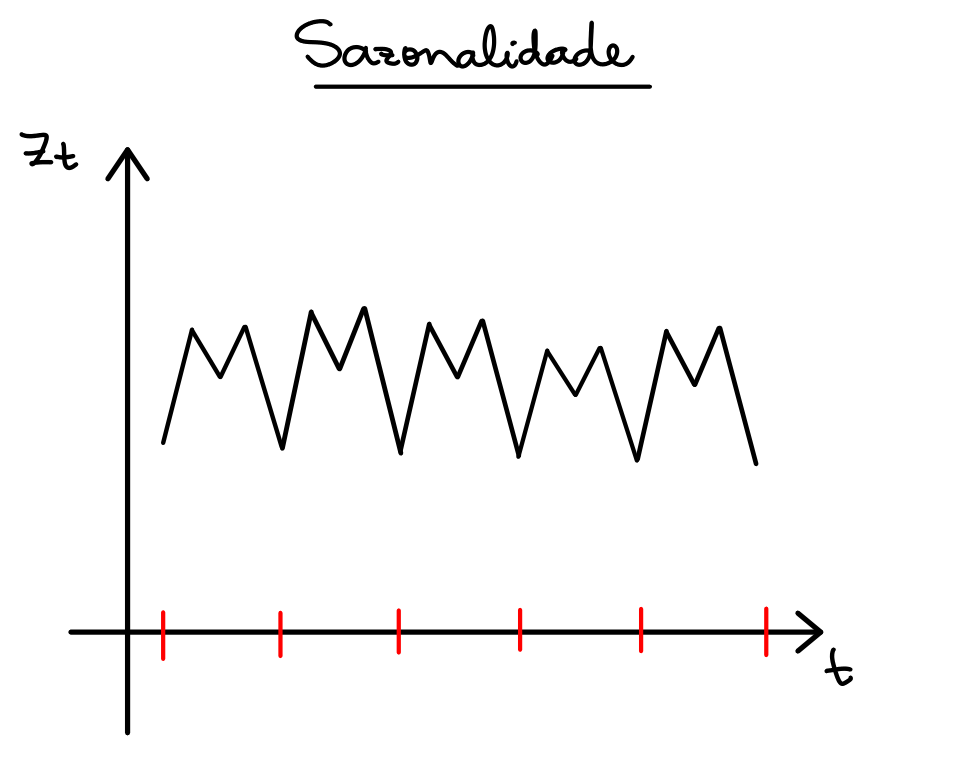

Considere as observações $\{Z_t, t=1,\ldots,N\}$ de uma série temporal.

Supondo que não existe tendência mas somente sazonalidade :

$$Z_t =  S_t + a_t$$

em que

- $S_t$ representa uma componente de **sazonalidade**

- $a_t$ é um ruído branco com média 0 e variância $\sigma^2_a$.

Se a sazonalidade for multiplicativa o modelo é definido como

$$Z_t =  S_t  a_t$$

**Métodos para estimar a sazonalidade**

Para obter a sazonalidade ajustada $\widehat{S_t}$, podemos utilizar diferentes métodos:

- **Método da regressão** (método determinístico) em que as covariáveis são variáveis periódicas, por exemplo seno, cosseno ou variáveis 'dummy', que são variáveis indicadoras  


- **Médias móveis** (método estocástico)

E então obtemos a série livre de sazonalidade (ou sazonalmente ajustada)


$$Y_t = Z_t - \widehat{S}_t, \text{  no caso aditivo, ou}$$


$$Y_t = Z_t / \widehat{S}_t \text{ no caso multiplicativo}$$

Aqui, nós usaremos a função [seasonal_decompose](https://www.statsmodels.org/dev/generated/statsmodels.tsa.seasonal.seasonal_decompose.html) do pacote [statsmodels](https://www.statsmodels.org/stable/index.html).

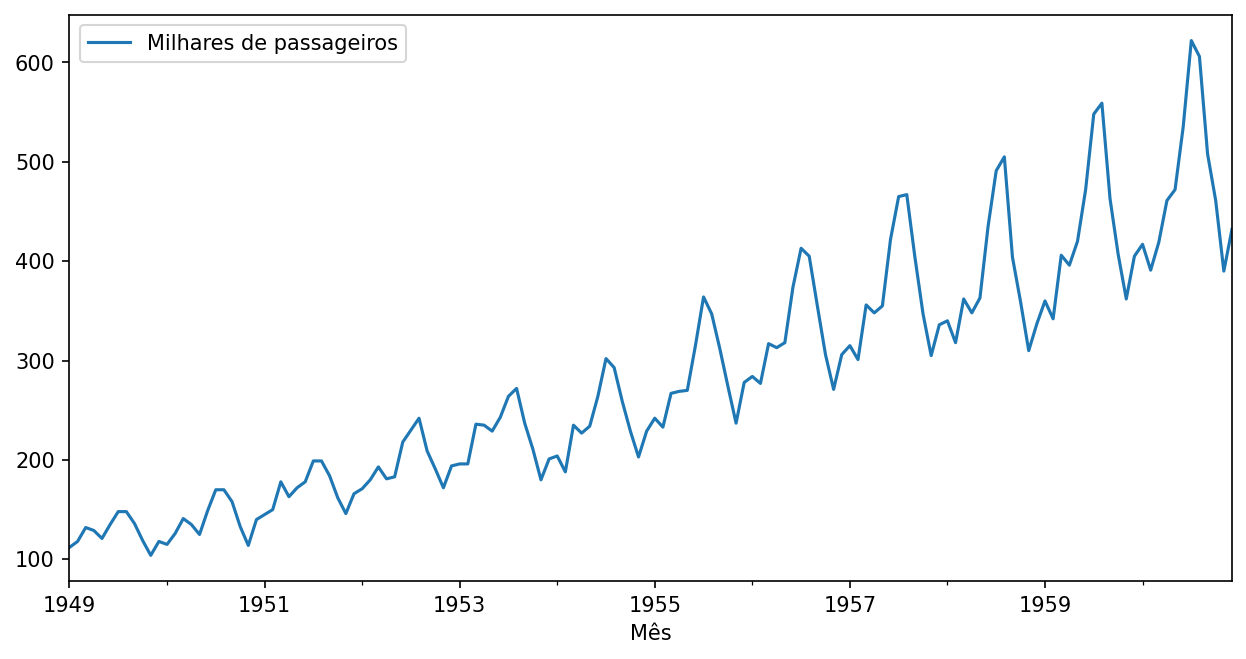

In [16]:
### Passageiros

# Agendamento de passageiros (em milhares) por mês na Pan Am nos Estados Unidos, observadas mensalmente no período de 1949-1960 (Brown, R. G. "Smoothing." Forecasting and Prediction of Discrete Time Series, 1963).
# A companhia usou os dados para prever a demanda futura e antes de programar compras e novas aeronaves e de treinar funcionários.

# Air Passengers: Passageiros aéreos
# Vamos ler os dados direto do github

url='https://raw.githubusercontent.com/cibelerusso/Aprendizado-Dinamico/main/Data/airline_passengers.csv'
passageiros = pd.read_csv(url, index_col=0,parse_dates=True)


passageiros.plot(figsize=(10,5));
passageiros.index = passageiros.index.to_period("M")


In [17]:
passageiros.tail

<bound method NDFrame.tail of          Milhares de passageiros
Mês                             
1949-01                      112
1949-02                      118
1949-03                      132
1949-04                      129
1949-05                      121
...                          ...
1960-08                      606
1960-09                      508
1960-10                      461
1960-11                      390
1960-12                      432

[144 rows x 1 columns]>

<Axes: xlabel='Mês'>

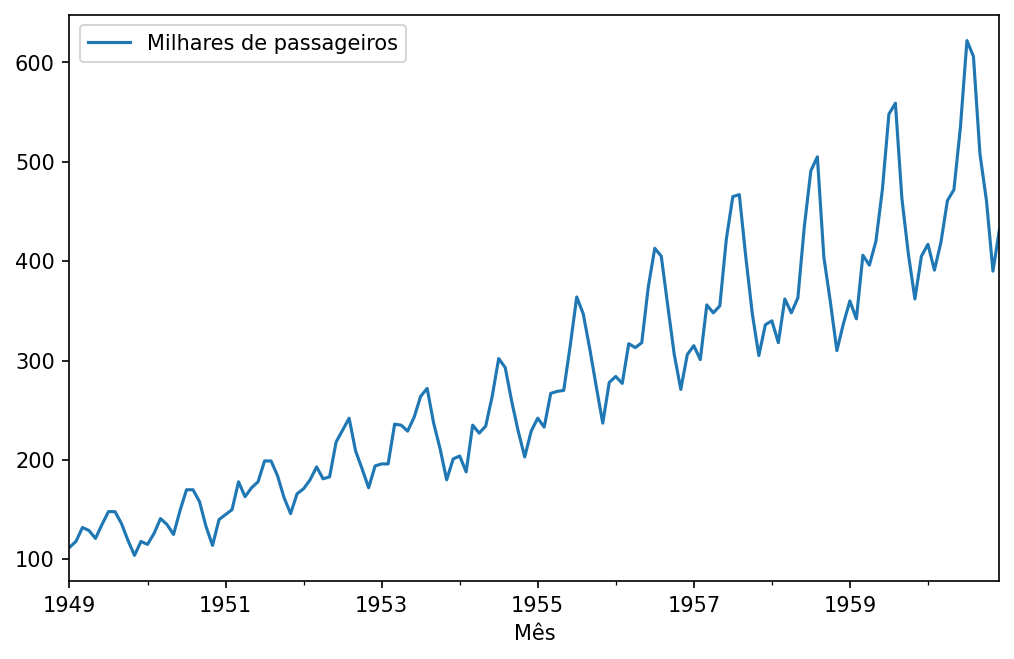

In [18]:
# Para essa análise, os dados faltantes devem ser excluídos!

passageiros = passageiros.dropna()

passageiros.plot()

# A sazonalidade é aditiva ou multiplicativa?


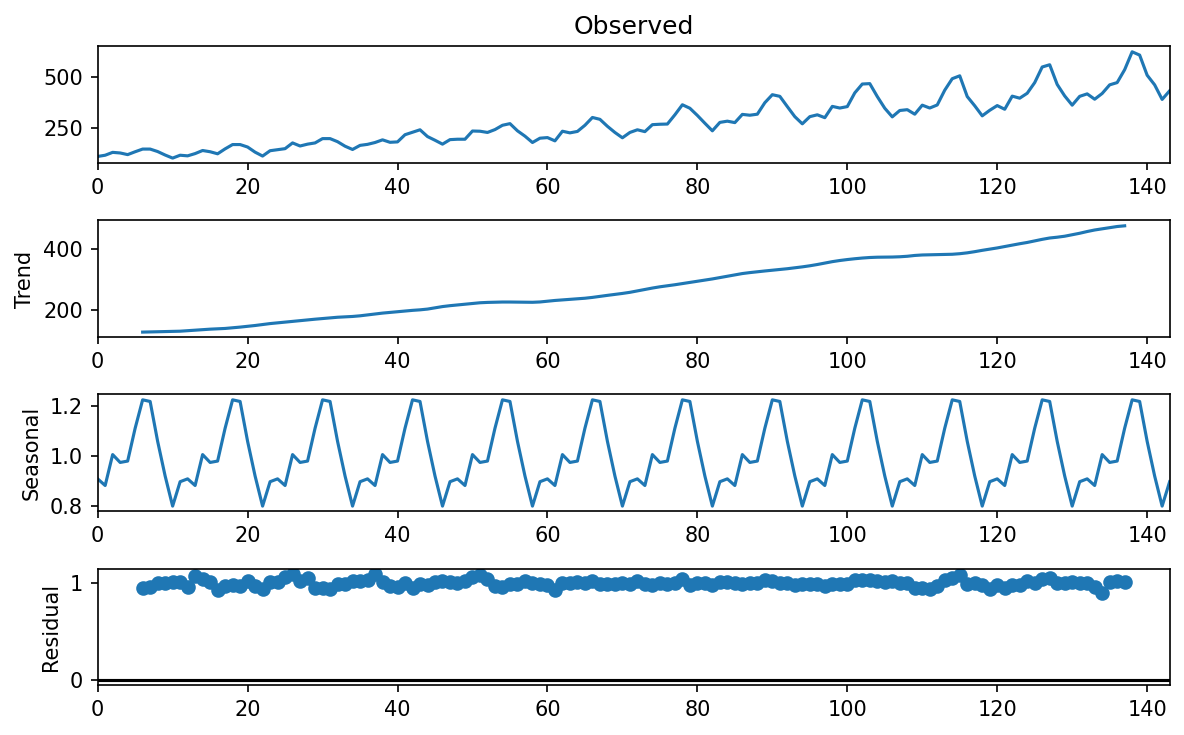

In [19]:
import statsmodels.api as sm

# Decomposição em tendência e sazonalidade

passag = np.array(passageiros['Milhares de passageiros'])

result = sm.tsa.seasonal_decompose(passag, model='multiplicative', period=12);

result.plot();


In [20]:
# Olhe para as componentes do objeto result

result.seasonal

array([0.91023037, 0.88362532, 1.00736629, 0.97590601, 0.98137803,
       1.11277583, 1.22655554, 1.21991097, 1.06049193, 0.92175724,
       0.80117808, 0.89882439, 0.91023037, 0.88362532, 1.00736629,
       0.97590601, 0.98137803, 1.11277583, 1.22655554, 1.21991097,
       1.06049193, 0.92175724, 0.80117808, 0.89882439, 0.91023037,
       0.88362532, 1.00736629, 0.97590601, 0.98137803, 1.11277583,
       1.22655554, 1.21991097, 1.06049193, 0.92175724, 0.80117808,
       0.89882439, 0.91023037, 0.88362532, 1.00736629, 0.97590601,
       0.98137803, 1.11277583, 1.22655554, 1.21991097, 1.06049193,
       0.92175724, 0.80117808, 0.89882439, 0.91023037, 0.88362532,
       1.00736629, 0.97590601, 0.98137803, 1.11277583, 1.22655554,
       1.21991097, 1.06049193, 0.92175724, 0.80117808, 0.89882439,
       0.91023037, 0.88362532, 1.00736629, 0.97590601, 0.98137803,
       1.11277583, 1.22655554, 1.21991097, 1.06049193, 0.92175724,
       0.80117808, 0.89882439, 0.91023037, 0.88362532, 1.00736

In [21]:
result.trend

array([         nan,          nan,          nan,          nan,
                nan,          nan, 126.79166667, 127.25      ,
       127.95833333, 128.58333333, 129.        , 129.75      ,
       131.25      , 133.08333333, 134.91666667, 136.41666667,
       137.41666667, 138.75      , 140.91666667, 143.16666667,
       145.70833333, 148.41666667, 151.54166667, 154.70833333,
       157.125     , 159.54166667, 161.83333333, 164.125     ,
       166.66666667, 169.08333333, 171.25      , 173.58333333,
       175.45833333, 176.83333333, 178.04166667, 180.16666667,
       183.125     , 186.20833333, 189.04166667, 191.29166667,
       193.58333333, 195.83333333, 198.04166667, 199.75      ,
       202.20833333, 206.25      , 210.41666667, 213.375     ,
       215.83333333, 218.5       , 220.91666667, 222.91666667,
       224.08333333, 224.70833333, 225.33333333, 225.33333333,
       224.95833333, 224.58333333, 224.45833333, 225.54166667,
       228.        , 230.45833333, 232.25      , 233.91

# Suavização e Alisamento exponencial



## Suavização

- A suavização permite que a tendência da série em um instante t possa ser estimada usando-se observações $Z_s$ com $s$ ao redor de $t$, por exemplo, usando as observações $Z_{t-n},Z_{t-n+1},\ldots, Z_{t+n}$ para estimar $T_t$.

- Procedimentos não paramétricos para aproximar localmente a série

- Transformação da série $Z_t$ em uma série $Z_t^{\star}$

Considere que as observações da série temporal $\{Z_t\}$ possam ser localmente decompostas em seu nível e mais um ruído aleatório

$$Z_t = \mu_t + a_t, \text{ para } t=1,\ldots, N$$

com $E(a_t)=0$ e $Var(a_t) = \sigma^2$ e $\mu_t$ é um parâmetro desconhecido, que pode variar lentamente com o tempo e que queremos estimar.



Alguns procedimentos de suavização:

- Médias móveis

- Medianas móveis

- Lowess

- Métodos de Holt-Winters




## Média móvel simples


Dadas as observações $Z_1,\ldots,Z_N$, a média móvel é dada por

$$Z_t^{\star} = M_t = \displaystyle{\frac{Z_t+Z_{t-1}+\ldots +Z_{t-(r+1)}}{r}},$$

ou

$$Z_t^{\star} = M_t = M_{t-1} + \displaystyle{\frac{Z_t-Z_{t-r}}{r}}$$



In [22]:
# Médias móveis para dados de passageiros aéreos

import pandas as pd
import numpy as np
%matplotlib inline

In [23]:
# Leitura dos dados

url = 'https://raw.githubusercontent.com/cibelerusso/Aprendizado-Dinamico/main/Data/airline_passengers.csv'

# Leitura via github
# Air Passengers: Passageiros aéreos
passageiros = pd.read_csv(url, index_col=0,parse_dates=True)

# Tirar dados faltantes pois influenciariam no cálculo da média móvel
passageiros = passageiros.dropna()

# OU poderia fazer simplesmente passageiros.dropna(inplace=True)

In [24]:
passageiros.head()

,Milhares de passageiros
Mês,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


Podemos criar uma série para a média móvel simples usando a função mean em rolling, que usa janelas deslizantes.
[Veja a documentação do rolling do pandas](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.rolling.html)




In [25]:
passageiros['MMS-6-meses'] = passageiros['Milhares de passageiros'].rolling(window=6).mean()
passageiros['MMS-12-meses'] = passageiros['Milhares de passageiros'].rolling(window=12).mean()

In [26]:
passageiros.head(15)

,Milhares de passageiros,MMS-6-meses,MMS-12-meses
Mês,,,
1949-01-01,112,NaN,NaN
1949-02-01,118,NaN,NaN
1949-03-01,132,NaN,NaN
1949-04-01,129,NaN,NaN
1949-05-01,121,NaN,NaN
1949-06-01,135,124.500000,NaN
1949-07-01,148,130.500000,NaN
1949-08-01,148,135.500000,NaN
1949-09-01,136,136.166667,NaN


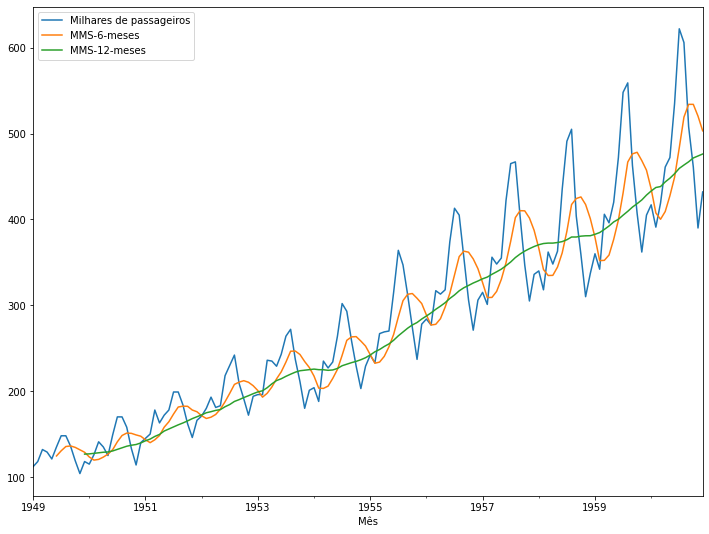

In [27]:
passageiros.plot(figsize=(12,9));

**Exercício:**

Crie um gráfico da mediana móvel. Quais as implicações?

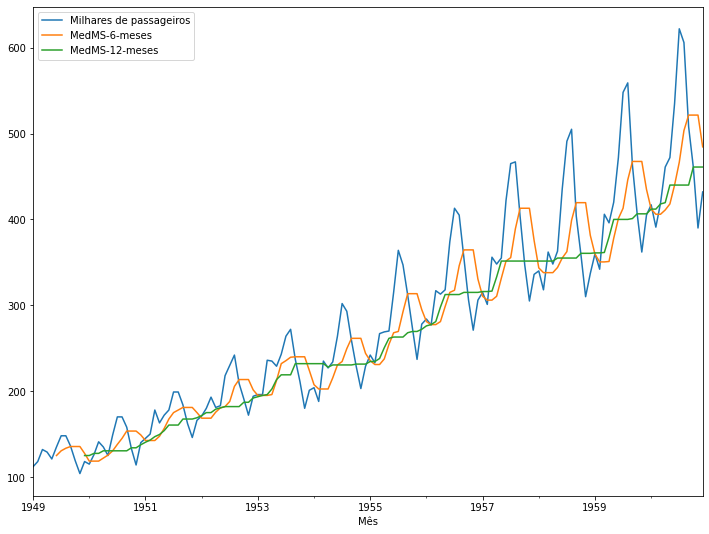

In [28]:
passageiros['MedMS-6-meses'] = passageiros['Milhares de passageiros'].rolling(window=6).median()
passageiros['MedMS-12-meses'] = passageiros['Milhares de passageiros'].rolling(window=12).median()

passageiros[['Milhares de passageiros','MedMS-6-meses','MedMS-12-meses']].plot(figsize=(12,9));

## Média móvel exponencialmente ponderada  (MMEP)

As médias móveis simples têm algumas desvantagens:

- Janelas menores levarão a mais ruído, em vez de sinal.
- Ele nunca alcançará o pico ou vale máximo dos dados devido ao cálculo da média.
- Valores históricos extremos podem distorcer significativamente a MMS



Uma possível proposta para contornar esses problemas é a **média móvel exponencialmente ponderada**.

A MMEP permite reduzir o efeito de atraso da MMS e dará mais peso aos valores que ocorreram mais recentemente (aplicando mais peso aos valores mais recentes, portanto, o nome). A quantidade de peso aplicada aos valores mais recentes dependerá dos parâmetros reais usados na MMEP e do número de períodos determinados pelo tamanho da janela.


A MMEP é dada por

$$\overline{Z}_t = \alpha Z_t + (1-\alpha) Z_{t-1},$$

com $\overline{Z}_0=Z_1$;  $t=1,\ldots,N,$ e $\alpha$ é uma constante tal que $0\leq\alpha\leq 1$.



Uma representação alternativa mais geral da MMEP implementada em Python é

$\overline{Z}_t =  \displaystyle \frac{\sum\limits_{i=0}^{t-1} w_i Z_{t-i}}{\sum\limits_{i=0}^{t-1} w_i}$

Aqui, $Z_t$ é a entrada, $w_i$ é o peso aplicado (Note que os pesos podem ser diferentes de $i=0$ a $(t-1)$), e $\overline{Z}_t$ é a saída.

Agora a questão é, como podemos definir o peso $w_i$?

Isso pode ser feito mudando valores do parâmetro adjust no método .ewm (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.ewm.html)

Quando <tt>adjust=True</tt> (default) as médias móveis ponderadas são calculadas usando pesos iguais a $w_i = (1 - \alpha)^i$

o que nos dá

$$\overline{Z}_t = \displaystyle\frac{Z_t + (1 - \alpha)Z_{t-1} + (1 - \alpha)^2 Z_{t-2} + \ldots+ (1 - \alpha)^{t-1} Z_{1}}{1 + (1 - \alpha) + (1 - \alpha)^2 + ...+ (1 - \alpha)^{t-1}}$$

Quando <tt>adjust=False</tt> as médias móveis são calculadas da forma

$\begin{array}{ll}\overline{Z}_0 &= Z_1 \\
\overline{Z}_t &= (1 - \alpha) Z_{t-1} + \alpha Z_t,\end{array}$

o que é equivalente a usar os pesos

$w_i = \begin{cases}
    \alpha (1 - \alpha)^i & \text{se } i < t \\
    (1 - \alpha)^i        & \text{se } i = t.
\end{cases}$

Quando adjust=True nós temos $\overline{Z}_0=Z_1$ e da última representação acima nós temos
$\overline{Z}_t=\alpha Z_t+(1−α)\overline{Z}_{t−1}$, portanto existe uma suposição que $Z_1$ não é um valor ordinário mas um momento exponencialmente ponderado das séries infinitas até aquele ponto.

Para o fator de suavização $\alpha$ tem-se que $0<\alpha≤1$ e é frequentemente mais fácil pensar ou em **span**, **centro de massa** ou **meia vida** de um momento exponencialmente ponderado

$\alpha =
 \begin{cases}
     \displaystyle\frac{2}{s + 1},               & \text{para span}\ s \geq 1\\
     \displaystyle\frac{1}{1 + c},               & \text{para centro de massa}\ c \geq 0\\
     \displaystyle 1 - \exp{\displaystyle(\frac{\log 0.5}{h})}, & \text{para meia-vida}\ h > 0
 \end{cases}$

* **Span** (período) corresponde ao que é comumente chamado uma "média móvel exponencialmente ponderada em N dias".
* **Centro de massa** tem uma interpretação física e pode ser pensado em termos do span: $c=(s−1)/2$
* **Meia-vida** é o período de tempo para o peso exponencial se reduzir pela metade.
* **Alpha** especifica o fator de suavização diretamente.

Temos que passar precisamente um dos parâmetros acima para a função .ewm(). Usaremos span=12.

In [29]:
passageiros['MMEP12'] = passageiros['Milhares de passageiros'].ewm(span=12,adjust=False).mean()

In [30]:
passageiros

,Milhares de passageiros,MMS-6-meses,MMS-12-meses,MedMS-6-meses,MedMS-12-meses,MMEP12
Mês,,,,,,
1949-01-01,112,NaN,NaN,NaN,NaN,112.000000
1949-02-01,118,NaN,NaN,NaN,NaN,112.923077
1949-03-01,132,NaN,NaN,NaN,NaN,115.857988
1949-04-01,129,NaN,NaN,NaN,NaN,117.879836
1949-05-01,121,NaN,NaN,NaN,NaN,118.359861
...,...,...,...,...,...,...
1960-08-01,606,519.166667,463.333333,503.5,440.0,494.898619
1960-09-01,508,534.000000,467.083333,521.5,440.0,496.914216
1960-10-01,461,534.000000,471.583333,521.5,461.0,491.388952


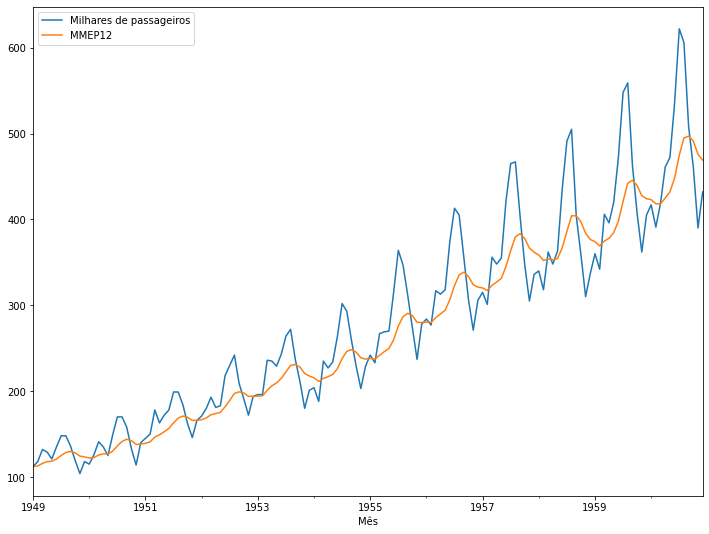

In [31]:
passageiros[['Milhares de passageiros','MMEP12']].plot(figsize=(12,9));

## Comparando MMS com MMEP

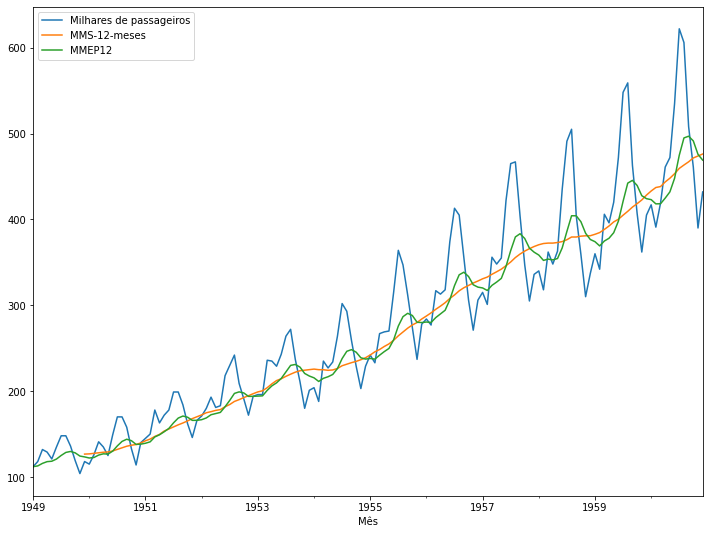

In [32]:
passageiros[['Milhares de passageiros','MMS-12-meses','MMEP12']].plot(figsize=(12,9)).autoscale(axis='x',tight=True);

**Exercício**

Aplique os métodos de média móvel (7 dias) e média exponencialmente ponderada (span=7) aos dados de mortes registradas por COVID-19 no estado de SP.


In [33]:
# Leitura dos dados

url = 'https://raw.githubusercontent.com/cibelerusso/Aprendizado-Dinamico/main/Data/covidSP.csv'

# Leitura via github
covidSP = pd.read_csv(url,index_col='date',parse_dates=True)


In [34]:
covidSP.head()

,confirmed,deaths
date,,
2020-02-26,0,0
2020-02-27,0,0
2020-02-28,1,0
2020-02-29,0,0
2020-03-01,0,0


In [35]:
covidSP['MMS-7-dias'] = covidSP['deaths'].rolling(window=7).mean()
covidSP['MMEP-7'] = covidSP['deaths'].ewm(span=7,adjust=False).mean()

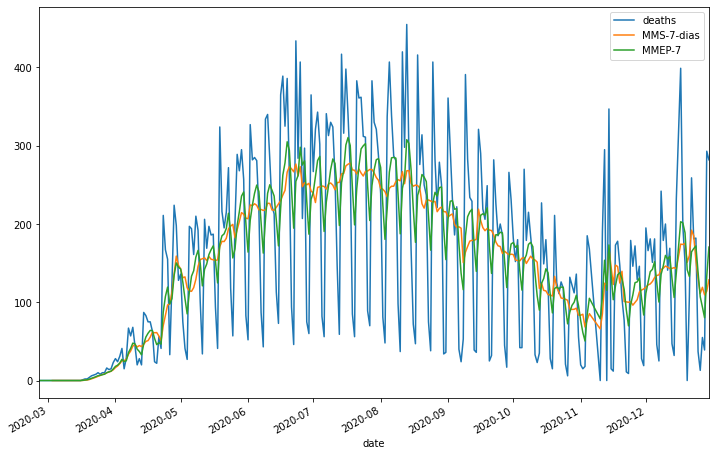

In [36]:
covidSP[['deaths','MMS-7-dias','MMEP-7']].plot(figsize=(12,8)).autoscale(axis='x',tight=True);

**Exercício**
Repita para 14 dias e span=14.
Compare esses resultados com os gráficos com 5 dias e span=5.
Você nota alguma relação com esses parâmetros e a suavidade da curva?

# Métodos de Suavização de Holt e Holt-Winters

por **Cibele Russo**

Baseado em

- MORETTIN, P. A.; TOLOI, C. M. C.. Análise de séries temporais: modelos lineares univariados. 3. ed. São Paulo: Blucher, 2018.

- EHLERS, R.S. Análise de Séries Temporais. ICMC USP. 2009.

Métodos de Holt e Holt-Winters:

- COWPERTWAIT, P. S.P., METCALFE, A. V. Introductory time series with R. Springer New York, NY, 2009.

- HYNDMAN, R. J., ATHANASOPOULOS, G.; Forecasting: principle and practice: O Texts; 2nd edition. 2018. Material sobre Holt-Winters disponível em https://otexts.com/fpp2/holt-winters.html. Acesso em 15/07/2024.

- HOLT, C.  Forecasting trends and seasonals by exponentially weighted averages. ONR. Memorandum no.52, p. 5-10, Carregie Institute of Technology.1957.

- WINTERS, P.R. Forecasting sales by exponentially weighted moving averages. Management Science, 6:324–342. 1960. DOI: https://doi.org/10.1287/mnsc.6.3.324

Implementações:

- BROWNLEE, J. Introduction to time series forecasting with python: how to prepare data and develop models to predict the future. Machine Learning Mastery, 2017.

- https://www.statsmodels.org/devel/generated/statsmodels.tsa.holtwinters.ExponentialSmoothing.html

- https://machinelearningmastery.com/exponential-smoothing-for-time-series-forecasting-in-python/

## MMS e MMEP

Na aula anterior, vimos métodos de suavização médias móveis e médias móveis exponencialmente ponderadas considerando a seguinte decomposição de uma série temporal $\{Z_t\}$

$$Z_t = \mu_t + a_t, \text{ para } t=1,\ldots, N$$

com $E(a_t)=0$ e $Var(a_t) = \sigma^2$ e $\mu_t$ um parâmetro desconhecido.

Esses métodos não levam em consideração que a série tem uma componente de tendência.

São técnicas descritivas não aconselháveis para fazer previsão.


**Queremos estimar a tendência e a sazonalidade, e com isso já podemos fazer previsões!**


Considere inicialmente que a série temporal seja composta localmente por soma de nível, tendência e erro aleatório (ruído), com média zero e variância constante $\sigma^2_a$, isto é

$$Z_t = \mu_t + T_t + a_t, \text{ com  } t=1,\ldots, N.$$



## Método de Holt

Parecido com a MMEP, porém utiliza uma nova constante para modelar a **tendência**

Os valores do nível e da tendência da série, no instante $t$, serão estimados por

$\overline{Z}_t = A Z_t + (1-A)(\overline{Z}_{t-1} + \widehat{T}_{t-1}),\ 0<A<1 \text{ e } t=2,\ldots,N$

$\widehat{T}_t = C (\overline{Z}_t - \overline{Z}_{t-1}) + (1-C) \widehat{T}_{t-1},\ 0<C<1 \text{ e } t=2,\ldots,N,$

respectivamente, $A$ e $C$ são denominadas constantes de suavização.


### Previsão

A previsão para o valor $Z_{t+h}$ com origem em $t$ é dada por

$\widehat{Z}_{t} (h)= \overline{Z}_t + h \widehat{T}_{t},\ \forall h>0$

ou seja, adiciona-se ao valor básico $\overline{Z}_t$ a tendência multiplicada pelo número de passos à frente que se deseja prever $(h)$.


Para atualizar a previsão, quando tivermos uma nova observação $Z_{t+1}$, podemos fazer

$\overline{Z}_{t+1} = A Z_{t+1} + (1-A)(\overline{Z}_{t} + \widehat{T}_{t}),$

$\widehat{T}_{t+1} = C (\overline{Z}_{t+1} - \overline{Z}_{t}) + (1-C) \widehat{T}_{t}$

e a nova previsão do valor $Z_{t+h}$ dado que temos uma nova observação $Z_{t+1}$ será

$$\widehat{Z}_{t+1}(h-1) = \overline{Z}_{t+1} + (h-1)\widehat{T}_{t+1}.$$

Precisamos assumir hipóteses sobre os valores iniciais, por exemplo, assumir que $\widehat{T}_2 = Z_2-Z_1$ e $\overline{Z}_2 = Z_2$. Se $Z_t$ for gerado por um processo $ARIMA(0,2,2)$, essa previsão será ótima.


As constantes $A$ e $C$ são escolhidas de forma que a soma dos erros quadráticos de previsão seja mínimo.

## Método de Holt-Winters

Para séries com padrão de comportamento mais complexo, existem outras formas de suavização, tais com os métodos de Holt-Winters.

Considere uma série sazonal com período $s$.

### Modelo com sazonalidade multiplicativa e tendência aditiva

$$Z_t = \mu_t F_t + T_t + a_t, \text{ com  } t=1,\ldots, N.$$

As três equações de suavização são dadas por

$\widehat{F}_t = D \left(\displaystyle\frac{Z_t}{\overline{Z}_t}\right) + (1-D)\widehat{F}_{t-s}, 0<D<1, t=s+1,\ldots,N$

$\overline{Z}_t = A  \left(\displaystyle\frac{Z_t}{\widehat{F}_{t-s}}\right) + (1-A)(\overline{Z}_{t-1} + \widehat{T}_{t-1}),\ 0<A<1 \text{ e } t=s+1,\ldots,N$

$\widehat{T}_t = C (\overline{Z}_t - \overline{Z}_{t-1}) + (1-C) \widehat{T}_{t-1},\ 0<C<1 \text{ e } t=s+1,\ldots,N,$

e representam estimativas do fator sazonal, do nível e da tendência, respectivamente, e $A$, $C$ e $D$ são constantes de suavização.




### Previsão


$\widehat{Z}_t(h) = (\overline{Z}_t+h \widehat{T}_t)\widehat{F}_{t+h-s}, h=1,2,\ldots,s$

$\widehat{Z}_t(h) = (\overline{Z}_t+h \widehat{T}_t)\widehat{F}_{t+h-2s}, h=s+1,\ldots,2s$

$\vdots \ \  \ \  =\ \  \ \   \vdots$

onde $\overline{Z}_t$, $\widehat{F}_t$ e $\widehat{T}_t$ são obtidos das equações do método.

Para fazermos atualizações das previsões, quando temos uma nova observação $Z_{t+1}$, utilizamos os valores

$\widehat{F}_{t+1} = D \displaystyle\left(\frac{Z_{t+1}}{\overline{Z}_{t+1}}\right) + (1-D)\widehat{F}_{{t+1}-s},$

$\overline{Z}_{t+1} = A  \displaystyle\left(\frac{Z_{t+1}}{\widehat{F}_{{t+1}-s}}\right) + (1-A)(\overline{Z}_{t} + \widehat{T}_{t}),$

$\widehat{T}_{t+1} = C (\overline{Z}_{t+1} - \overline{Z}_{t}) + (1-C) \widehat{T}_{t},$

e a nova previsão para a observação $Z_{t+h}$ será

$\widehat{Z}_{t+1}(h-1) = (\overline{Z}_{{t+1}}+(h-1)\widehat{T}_{t+1})\widehat{F}_{t+1+h-s}, h=1,2,\ldots,s+1$

$\widehat{Z}_{t+1}(h-1) = (\overline{Z}_{{t+1}}+(h-1)\widehat{T}_{t+1})\widehat{F}_{t+1+h-2s}, h=s+2,\ldots, 2s+1$


Também é necessário fazer suposições sobre os valores iniciais para o processo.

### Modelo com sazonalidade e tendência aditivas

$$Z_t = \mu_t + T_t +F_t+ a_t, \text{ com  } t=1,\ldots, N.$$

As estimativas do fator sazonal, do nível e da tendência da série são dadas por

$\widehat{F}_t = D   ({Z}_t - \overline{Z}_{t})+ (1-D)\widehat{F}_{t-s}, 0<D<1, t=s+1,\ldots,N$

$\overline{Z}_t = A  (Z_t - \widehat{F}_{t-s}) + (1-A)(\overline{Z}_{t-1} + \widehat{T}_{t-1}),\ 0<A<1 \text{ e } t=s+1,\ldots,N$

$\widehat{T}_t = C (\overline{Z}_t - \overline{Z}_{t-1}) + (1-C) \widehat{T}_{t-1},\ 0<C<1 \text{ e } t=s+1,\ldots,N,$

respectivamente, e $A$, $C$ e $D$ são constantes de suavização e são estimadas de forma que minimizem a soma dos quadrados dos erros dos ajustes.

### Previsão


$\widehat{Z}_t(h) = \overline{Z}_t+h \widehat{T}_t + \widehat{F}_{t+h-s}, h=1,2,\ldots,s$

$\widehat{Z}_t(h) = \overline{Z}_t+h \widehat{T}_t + \widehat{F}_{t+h-2s}, h=s+1,\ldots,2s$

$\vdots \ \  \ \  =\ \  \ \   \vdots$

onde $\overline{Z}_t$, $\widehat{F}_t$ e $\widehat{T}_t$ são obtidos das equações do método.

Para fazermos atualizações das previsões, quando temos uma nova observação $Z_{t+1}$, utilizamos os valores

$\widehat{F}_{t+1} = D   (Z_{t+1} - \overline{Z}_{t+1})+ (1-D)\widehat{F}_{t+1-s}, $

$\overline{Z}_{t+1} = A  (Z_{t+1} - \widehat{F}_{{t+1}-s}) + (1-A)(\overline{Z}_{{t}} + \widehat{T}_{{t}}),$

$\widehat{T}_{t+1} = C (\overline{Z}_{t+1} - \overline{Z}_{t}) + (1-C) \widehat{T}_{t},$


e a nova previsão para a observação $Z_{t+h}$ será

$\widehat{Z}_{t+1}(h-1) = \overline{Z}_{{t+1}}+(h-1)\widehat{T}_{t+1} + \widehat{F}_{t+1+h-s}, h=1,2,\ldots,s+1$

$\widehat{Z}_{t+1}(h-1) = \overline{Z}_{{t+1}}+(h-1)\widehat{T}_{t+1}+\widehat{F}_{t+1+h-2s}, h=s+2,\ldots, 2s+1$

Também é necessário fazer suposições sobre os valores iniciais para o processo.

Se $Z_t$ for gerado por um processo $ARIMA$, essa previsão será ótima.



## Visão geral de vantagens e desvantagens dos métodos de suavização

### Média móvel simples 

- Simples implementação;

- Aplicável mesmo com um número pequeno de observações;

- Flexibilidade de acordo com o tamanho da janela

Porém

- Método descritivo e não recomendável para previsões



### Média móvel exponencialmente ponderada 

- Fácil compreensão e aplicabilidade;

- Necessidade de armazenar somente $Z_t$, $\overline{Z}_t$ e $\alpha$

Porém

- Método descritivo e não recomendável para previsões


### Método de Holt 

- Pode ser usado para prever séries que tem tendência

- Apresenta um nível maior de dificuldade para encontrar os valores apropriados para as constantes de suavização $A$ e $C$, em geral que minimizem a soma dos quadrados dos erros dos ajustes

### Método de Holt-Winters 

- Pode ser usado para prever séries que tem tendência e sazonalidade, seja ela aditiva ou multiplicativa

Porém

- Impossibilidade e dificuldade para estudar propriedades estatísticas como média e variância das previsões, e consequentemente construção de intervalos de confiança para as previsões

- Nível maior de dificuldade para encontrar os valores apropriados para as constantes de suavização $A$, $C$ e $D$, em geral que minimizem a soma dos quadrados dos erros dos ajustes

### Aplicação: dados de passageiros aéreos

In [37]:
import pandas as pd
import numpy as np
%matplotlib inline


# Ignorar warnings não prejudiciais
import warnings
warnings.filterwarnings("ignore")


In [38]:
passageiros = pd.read_csv('https://raw.githubusercontent.com/cibelerusso/Aprendizado-Dinamico/main/Data/airline_passengers.csv', index_col=0, parse_dates=True)
passageiros.head()

,Milhares de passageiros
Mês,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [39]:
passageiros.index

DatetimeIndex(['1949-01-01', '1949-02-01', '1949-03-01', '1949-04-01',
               '1949-05-01', '1949-06-01', '1949-07-01', '1949-08-01',
               '1949-09-01', '1949-10-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[ns]', name='Mês', length=144, freq=None)

**Estabeleça a frequência do DatetimeIndex!**

Para construir um modelo de suavização Holt-Winters, o pacote statsmodels precisa saber a frequência dos dados. Para os dados de passageiros aéreos, as observações são coletadas no início do mês, usaremos MS.

Veja <a href='http://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases'>aqui</a> uma lista de possibilidades.

In [40]:
passageiros.index.freq = 'MS'
passageiros.index

DatetimeIndex(['1949-01-01', '1949-02-01', '1949-03-01', '1949-04-01',
               '1949-05-01', '1949-06-01', '1949-07-01', '1949-08-01',
               '1949-09-01', '1949-10-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[ns]', name='Mês', length=144, freq='MS')


## Suavização exponencial simples

Uma variação da função Holt-Winters de statsmodels apresenta a Suavização exponencial simples, que fornece os mesmos cálculos da média móvel exponencialmente ponderada do método .ewm do pandas que vimos na última aula.

 $\begin{align}\overline{Z}_0 &= Z_1 \\
\overline{Z}_t &= (1 - \alpha) Z_{t-1} + \alpha Z_t,\end{align}$


In [41]:
# É possível ajustar a MMEP usando o pacote statsmodels.tsa.holtwinters e a função SimpleExpSmoothing

from statsmodels.tsa.holtwinters import SimpleExpSmoothing

span = 12
alpha = 2/(span+1)

passageiros['MMEP12'] = passageiros['Milhares de passageiros'].ewm(alpha=alpha,adjust=False).mean()
passageiros['SES12'] = SimpleExpSmoothing(passageiros['Milhares de passageiros']).fit(smoothing_level=alpha,optimized=False).fittedvalues.shift(-1)
passageiros.head()

,Milhares de passageiros,MMEP12,SES12
Mês,,,
1949-01-01,112,112.000000,112.000000
1949-02-01,118,112.923077,112.923077
1949-03-01,132,115.857988,115.857988
1949-04-01,129,117.879836,117.879836
1949-05-01,121,118.359861,118.359861


## Método de Holt

In [42]:
# Método de Holt

from statsmodels.tsa.api import ExponentialSmoothing


modelo =  ExponentialSmoothing(passageiros['Milhares de passageiros'], trend='add');

ajustado = modelo.fit();

passageiros['Holt'] = ajustado.fittedvalues.shift(-1);

passageiros.head()



,Milhares de passageiros,MMEP12,SES12,Holt
Mês,,,,
1949-01-01,112,112.000000,112.000000,114.102394
1949-02-01,118,112.923077,112.923077,120.040657
1949-03-01,132,115.857988,115.857988,134.001539
1949-04-01,129,117.879836,117.879836,131.085845
1949-05-01,121,118.359861,118.359861,123.110263


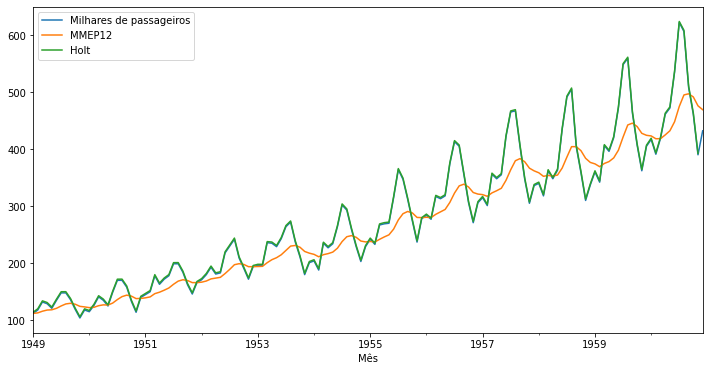

In [43]:
passageiros[['Milhares de passageiros','MMEP12','Holt']].plot(figsize=(12,6)).autoscale(axis='x',tight=True);

**Podemos notar que o método de Holt já apresenta um ajuste bem melhor do que a MMEP!**

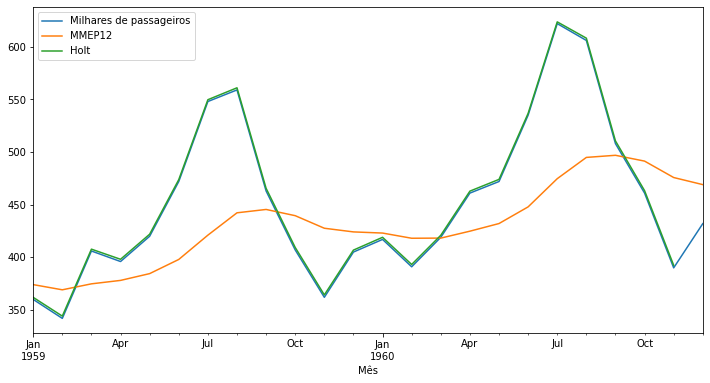

In [44]:
passageiros[['Milhares de passageiros','MMEP12','Holt']].iloc[-24:].plot(figsize=(12,6)).autoscale(axis='x',tight=True);

## Método de Holt-Winters - sazonalidade aditiva ou multiplicativa

In [45]:
# Ajuste do modelo pelo Método de Holt-Winters com sazonalidade aditiva

modelo =  ExponentialSmoothing(passageiros['Milhares de passageiros'],trend='add',seasonal='add',seasonal_periods=12);

ajustado = modelo.fit();

passageiros['Holt-Winters-adit-12'] = ajustado.fittedvalues;

passageiros.head()


,Milhares de passageiros,MMEP12,SES12,Holt,Holt-Winters-adit-12
Mês,,,,,
1949-01-01,112,112.000000,112.000000,114.102394,112.006984
1949-02-01,118,112.923077,112.923077,120.040657,120.149251
1949-03-01,132,115.857988,115.857988,134.001539,134.693302
1949-04-01,129,117.879836,117.879836,131.085845,131.367738
1949-05-01,121,118.359861,118.359861,123.110263,124.625107


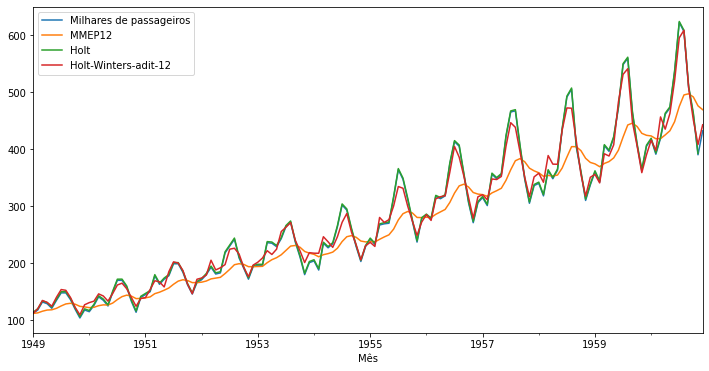

In [46]:
passageiros[['Milhares de passageiros','MMEP12','Holt', 'Holt-Winters-adit-12']].plot(figsize=(12,6)).autoscale(axis='x',tight=True);

In [47]:
# Ajuste do modelo pelo Método de Holt-Winters com sazonalidade multiplicativa

modelo =  ExponentialSmoothing(passageiros['Milhares de passageiros'],trend='add',seasonal='mul',seasonal_periods=12)

ajustado = modelo.fit()

passageiros['Holt-Winters-mult-12'] = ajustado.fittedvalues

passageiros.tail()

,Milhares de passageiros,MMEP12,SES12,Holt,Holt-Winters-adit-12,Holt-Winters-mult-12
Mês,,,,,,
1960-08-01,606,494.898619,494.898619,608.168786,608.232648,625.005552
1960-09-01,508,496.914216,496.914216,510.571382,507.657627,506.744124
1960-10-01,461,491.388952,491.388952,463.313463,451.326089,443.213013
1960-11-01,390,475.790652,475.790652,392.424879,407.931700,393.492899
1960-12-01,432,469.053629,NaN,NaN,442.600418,432.351059


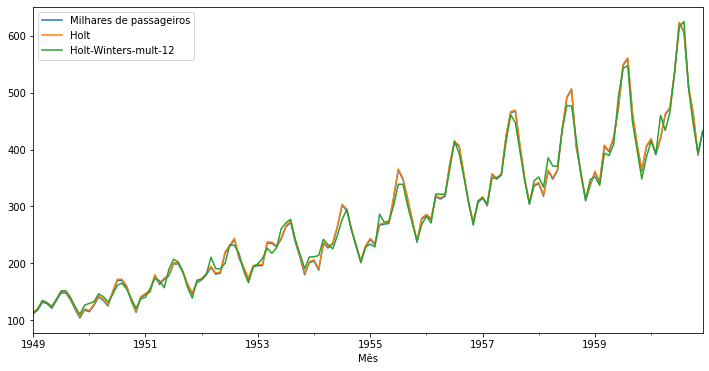

In [48]:
passageiros[['Milhares de passageiros','Holt','Holt-Winters-mult-12']].plot(figsize=(12,6)).autoscale(axis='x',tight=True);

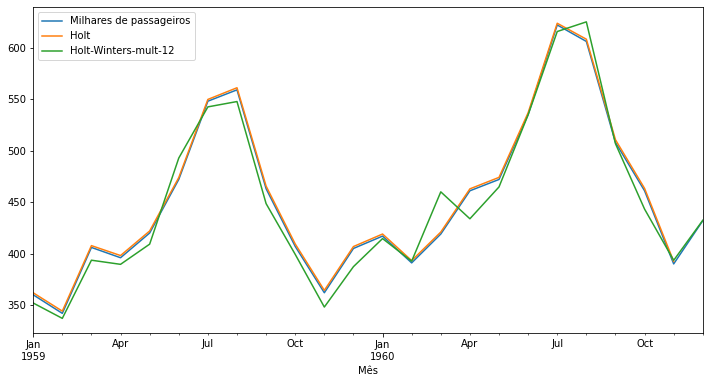

In [49]:
## Olhando somente para os últimos dois anos

passageiros[['Milhares de passageiros','Holt','Holt-Winters-mult-12']].iloc[-24:].plot(figsize=(12,6)).autoscale(axis='x',tight=True);

Aparentemente, o método de Holt está performando melhor para esses dados.

Vamos ver como se comportam na predição de observações futuras?


In [50]:
len(passageiros)

144


## Previsão com o método Holt-Winters

Neste exemplo, usaremos o mesmo conjunto de dados airlines_passengers e os dividiremos em 108 registros de treinamento e 36 registros de teste. Em seguida, avaliaremos o desempenho do modelo.


In [51]:
import pandas as pd
import numpy as np
%matplotlib inline

url='https://raw.githubusercontent.com/cibelerusso/Aprendizado-Dinamico/main/Data/airline_passengers.csv'
passageiros = pd.read_csv(url, index_col=0, parse_dates=True)


passageiros.index.freq = 'MS'
passageiros.head()

,Milhares de passageiros
Mês,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [52]:
passageiros.tail()

,Milhares de passageiros
Mês,
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390
1960-12-01,432


In [53]:
passageiros.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Freq: MS
Data columns (total 1 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Milhares de passageiros  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB


## Divisão da base em treino e teste

In [54]:
len(passageiros)

144

In [55]:
108/144

0.75

In [56]:
dados_treino = passageiros.iloc[:108] # Dados de treinamento até observação 108, sem incluí-la
dados_teste = passageiros.iloc[108:] # Dados de teste a partir da observação 108

## Ajuste do modelo

In [57]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

ajustado_HW = ExponentialSmoothing(dados_treino['Milhares de passageiros'],trend='add',seasonal='mul',seasonal_periods=12).fit()


## Avaliação do modelo com predições para dados de teste

In [58]:
predito_HW = ajustado_HW.forecast(36).rename('Previsão Holt-Winters')



In [59]:
predito_HW.head()

1958-01-01    343.512143
1958-02-01    335.465298
1958-03-01    388.891944
1958-04-01    378.396546
1958-05-01    379.937308
Freq: MS, Name: Previsão Holt-Winters, dtype: float64

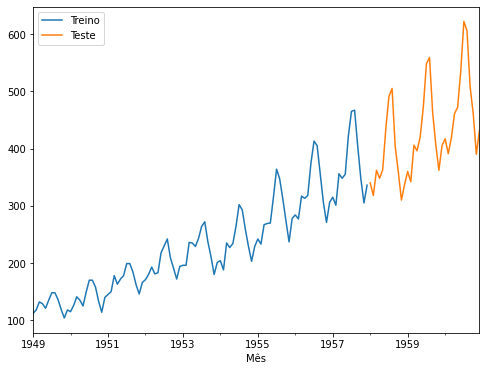

In [60]:
dados_treino['Milhares de passageiros'].plot(legend=True,label='Treino')
dados_teste['Milhares de passageiros'].plot(legend=True,label='Teste',figsize=(8,6));

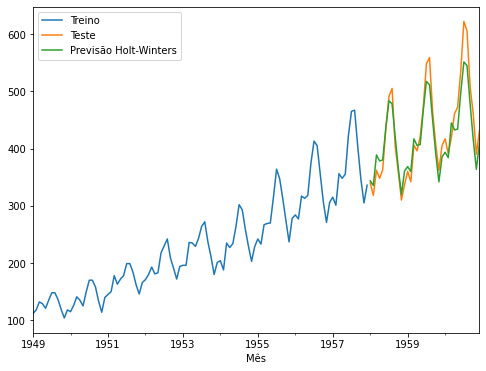

In [61]:
dados_treino['Milhares de passageiros'].plot(legend=True,label='Treino')
dados_teste['Milhares de passageiros'].plot(legend=True,label='Teste',figsize=(8,6))

predito_HW.plot(legend=True,label='Previsão Holt-Winters');



**Exercício: Obtenha a previsão pelo Método de Holt**


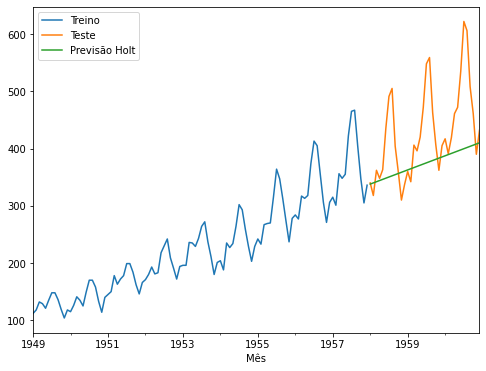

In [62]:
ajustado_H = ExponentialSmoothing(dados_treino['Milhares de passageiros'],trend='add').fit()
predito_H = ajustado_H.forecast(36).rename('Previsão Holt')


dados_treino['Milhares de passageiros'].plot(legend=True,label='Treino')
dados_teste['Milhares de passageiros'].plot(legend=True,label='Teste',figsize=(8,6))
predito_H.plot(legend=True,label='Previsão Holt');

## Métricas de avaliação dos ajustes

Para avaliar a distância da predição para o valor ajustado, usamos o erro quadrático médio e o erro absoluto médio

### Erro quadrático médio


$EQM = MSE = \displaystyle\sum_ {i=t+1}^{k}\frac{({Z_i - \widehat{Z}_i})^2}{k-t-1}$


### Erro absoluto médio

$EAM = MAE =  \displaystyle\sum_ {i=t+1}^{k}\frac{|{Z_t - \widehat{Z}_t}|}{k-t-1}$


In [63]:
from sklearn.metrics import mean_squared_error,mean_absolute_error

In [64]:
mean_absolute_error(dados_teste,predito_HW)

22.629311210003227

In [65]:
mean_absolute_error(dados_teste,predito_H)

63.343307065273606

In [66]:
mean_squared_error(dados_teste,predito_HW)

749.0304177969965

In [67]:
mean_squared_error(dados_teste,predito_H)

7791.631326444599

In [68]:
np.sqrt(mean_squared_error(dados_teste,predito_HW))

27.36842008222244

In [69]:
np.sqrt(mean_squared_error(dados_teste,predito_H))

88.27021766396976

In [70]:
dados_teste.describe()

,Milhares de passageiros
count,36.000000
mean,428.500000
std,79.329152
min,310.000000
25%,362.000000
50%,412.000000
75%,472.000000
max,622.000000


In [71]:
predito_HW.describe()

count     36.000000
mean     418.350044
std       59.952333
min      319.756686
25%      375.928394
50%      408.394148
75%      453.700127
max      551.342174
Name: Previsão Holt-Winters, dtype: float64

In [72]:
predito_H.describe()

count     36.000000
mean     373.968065
std       21.704398
min      337.916485
25%      355.942275
50%      373.968065
75%      391.993855
max      410.019644
Name: Previsão Holt, dtype: float64

## Previsão para os dados da COVID-19

In [73]:
# Dados de COVID-19 no estado de SP

import pandas as pd
import numpy as np
%matplotlib inline

covidSP = pd.read_csv('https://raw.githubusercontent.com/cibelerusso/Aprendizado-Dinamico/main/Data/covidSP.csv', index_col=0, parse_dates=True)
covidSP.index = pd.to_datetime(covidSP.index)

In [74]:
covidSP.head()

,confirmed,deaths
date,,
2020-02-26,0,0
2020-02-27,0,0
2020-02-28,1,0
2020-02-29,0,0
2020-03-01,0,0


In [75]:
covidSP.index.min()

Timestamp('2020-02-26 00:00:00')

In [76]:
covidSP.index.max()

Timestamp('2020-12-30 00:00:00')

In [77]:
idx = pd.date_range(start='2020-02-28', end='2020-12-30', freq='D')
idx

DatetimeIndex(['2020-02-28', '2020-02-29', '2020-03-01', '2020-03-02',
               '2020-03-03', '2020-03-04', '2020-03-05', '2020-03-06',
               '2020-03-07', '2020-03-08',
               ...
               '2020-12-21', '2020-12-22', '2020-12-23', '2020-12-24',
               '2020-12-25', '2020-12-26', '2020-12-27', '2020-12-28',
               '2020-12-29', '2020-12-30'],
              dtype='datetime64[ns]', length=307, freq='D')

In [78]:
covidSP = covidSP.reindex(idx)
covidSP.head(30)

,confirmed,deaths
2020-02-28,1.0,0.0
2020-02-29,0.0,0.0
2020-03-01,0.0,0.0
2020-03-02,0.0,0.0
2020-03-03,0.0,0.0
2020-03-04,1.0,0.0
2020-03-05,3.0,0.0
2020-03-06,4.0,0.0
2020-03-07,3.0,0.0
2020-03-08,3.0,0.0


In [79]:
covidSP.fillna(0,inplace=True)
covidSP.head(30)

,confirmed,deaths
2020-02-28,1.0,0.0
2020-02-29,0.0,0.0
2020-03-01,0.0,0.0
2020-03-02,0.0,0.0
2020-03-03,0.0,0.0
2020-03-04,1.0,0.0
2020-03-05,3.0,0.0
2020-03-06,4.0,0.0
2020-03-07,3.0,0.0
2020-03-08,3.0,0.0


In [80]:
len(covidSP)

307

In [81]:
covidSP.index

DatetimeIndex(['2020-02-28', '2020-02-29', '2020-03-01', '2020-03-02',
               '2020-03-03', '2020-03-04', '2020-03-05', '2020-03-06',
               '2020-03-07', '2020-03-08',
               ...
               '2020-12-21', '2020-12-22', '2020-12-23', '2020-12-24',
               '2020-12-25', '2020-12-26', '2020-12-27', '2020-12-28',
               '2020-12-29', '2020-12-30'],
              dtype='datetime64[ns]', length=307, freq='D')

## Divisão da base em treino e teste


In [82]:
dados_treino = covidSP.iloc[:286] # Dados de treinamento até observação 286, sem incluí-la
dados_teste = covidSP.iloc[286:] # Dados de teste a partir da observação 286

In [83]:
dados_treino

,confirmed,deaths
2020-02-28,1.0,0.0
2020-02-29,0.0,0.0
2020-03-01,0.0,0.0
2020-03-02,0.0,0.0
2020-03-03,0.0,0.0
...,...,...
2020-12-05,8938.0,181.0
2020-12-06,2675.0,46.0
2020-12-07,1116.0,25.0
2020-12-08,7923.0,242.0


In [84]:
## Ajuste do modelo
from statsmodels.tsa.holtwinters import ExponentialSmoothing


ajustado = ExponentialSmoothing(dados_treino['deaths'],trend='add',seasonal='add',seasonal_periods=7).fit()

In [85]:
# Previsão

predito = ajustado.forecast(21).rename('Previsão Holt-Winters')

In [86]:
predito.index = covidSP.index[286:]
predito.index

DatetimeIndex(['2020-12-10', '2020-12-11', '2020-12-12', '2020-12-13',
               '2020-12-14', '2020-12-15', '2020-12-16', '2020-12-17',
               '2020-12-18', '2020-12-19', '2020-12-20', '2020-12-21',
               '2020-12-22', '2020-12-23', '2020-12-24', '2020-12-25',
               '2020-12-26', '2020-12-27', '2020-12-28', '2020-12-29',
               '2020-12-30'],
              dtype='datetime64[ns]', freq='D')

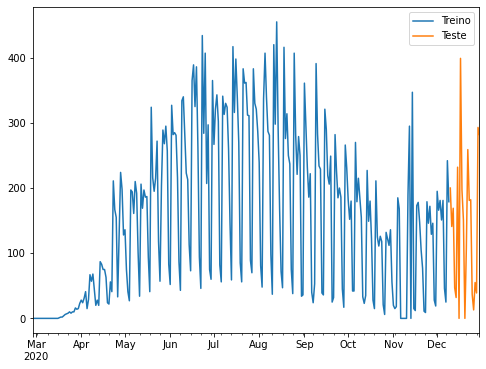

In [87]:
dados_treino['deaths'].plot(legend=True,label='Treino')
dados_teste['deaths'].plot(legend=True,label='Teste',figsize=(8,6));


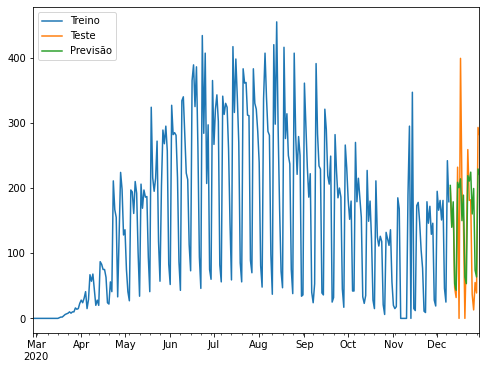

In [88]:
dados_treino['deaths'].plot(legend=True,label='Treino')
dados_teste['deaths'].plot(legend=True,label='Teste',figsize=(8,6))
predito.plot(legend=True,label='Previsão');

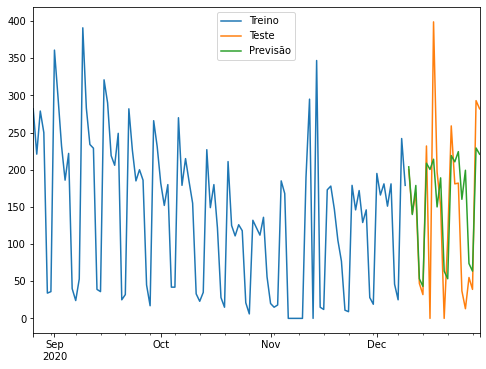

In [89]:
dados_treino['deaths'].iloc[180:].plot(legend=True,label='Treino')
dados_teste['deaths'].plot(legend=True,label='Teste',figsize=(8,6))
predito.plot(legend=True,label='Previsão');

In [90]:
## Ajuste do modelo com sazonalidade multiplicativa
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Precisamos considerar somente os dados positivos, mas vamos considerar os dados entre o início de maio e o início de setembro

In [91]:
covidSP = covidSP.loc['2020-05-01':'2020-09-01']

In [92]:
len(covidSP)

124

In [93]:
dados_treino = covidSP.iloc[:103] # Dados de treinamento até observação 240, sem incluí-la
dados_teste = covidSP.iloc[103:] # Dados de teste a partir da observação 240

In [94]:
ajustado = ExponentialSmoothing(dados_treino['deaths'],trend='add',seasonal='mul',seasonal_periods=7).fit()

In [95]:
predito = ajustado.forecast(21).rename('Previsão Holt-Winters')
predito.index = covidSP.index[103:]


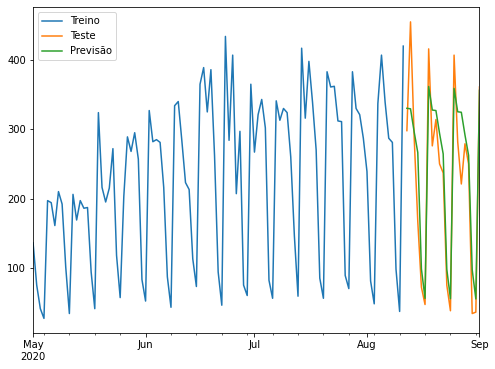

In [96]:
dados_treino['deaths'].plot(legend=True,label='Treino')
dados_teste['deaths'].plot(legend=True,label='Teste',figsize=(8,6))
predito.plot(legend=True,label='Previsão');

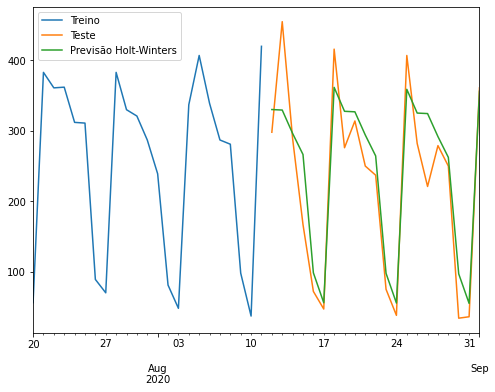

In [97]:
dados_treino['deaths'].iloc[80:].plot(legend=True,label='Treino')
dados_teste['deaths'].plot(legend=True,label='Teste',figsize=(8,6))
predito.plot(legend=True,label='Previsão Holt-Winters');

# O que vem mais adiante:

- Estacionariedade das séries

- Funções de autocovariância, autocorrelação

- Modelos ARMA, ARIMA, SARIMA, SARIMAX

- Métodos de previsão: Previsão Bayesiana, passo-a-frente, previsão dinâmica, Theta

- Modelos de redes neurais artificiais: GRU, LSTM

## Boxplots por períodos

Veja mais em

https://pt.wikipedia.org/wiki/Diagrama_de_caixa

https://seaborn.pydata.org/generated/seaborn.boxplot.html

<Axes: xlabel='Ano', ylabel='Milhares de passageiros'>

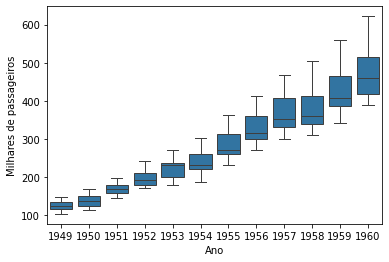

In [98]:
import seaborn as sns

passageiros['Ano'] = passageiros.index.year

sns.boxplot(x=passageiros['Ano'], y=passageiros['Milhares de passageiros'])

<Axes: xlabel='Week', ylabel='deaths'>

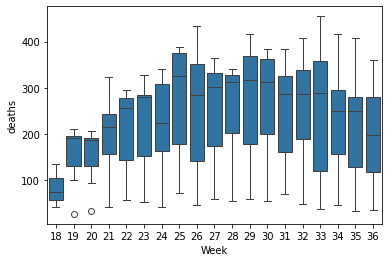

In [99]:
import seaborn as sns

covidSP['Week'] = covidSP.index.isocalendar().week

sns.boxplot(x=covidSP['Week'], y=covidSP['deaths'])

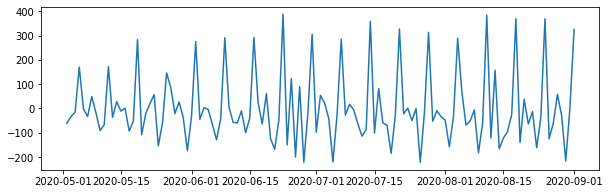

In [100]:
# Primeiras diferenças
y = np.diff(covidSP['deaths'])
x = covidSP.index[1:]


plt.rcParams['figure.figsize'] = [10,3]
plt.plot(x,y)


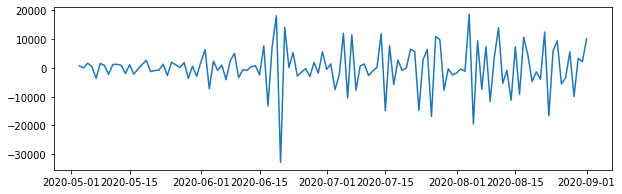

In [101]:
# Segundas diferenças

y = np.diff(np.diff(covidSP['confirmed']))
x = covidSP.iloc[2:].index


plt.rcParams['figure.figsize'] = [10,3]
plt.plot(x,y);





## Correlograma

O correlograma é uma representação das autocorrelações entre as observações da série temporal.

Ou seja, cada ponto do gráfico representa a correlação entre a série original e a série com o atraso correspondente.

## Autocorrelação parcial

A autocorrelação parcial é uma medida de associação linear de duas variáveis após remover o efeito de outras variáveis que afetam ambas. Ou seja, a autocorrelação parcial com atraso $k$ é a autocorrelação entre $y_t$ e $y_ {t + k}$ em que não são contabilizados os atrasos entre $1$ e $k - 1$.

Na prática, modelos lineares são ajustados para a série "corrente" com a série em atraso como preditor, e os resíduos desse modelo são utilizados para o próximo passo, calcula-se a correlação entre os resíduos e a próxima série em atraso e assim por diante.





## Aplicações

In [102]:
import pandas as pd
import numpy as np
import matplotlib as plt
%matplotlib inline
import statsmodels.api as sm

# Ignorar warnings não prejudiciais
import warnings
warnings.filterwarnings("ignore")

plt.rcParams['figure.dpi'] = 150

# Dados Passageiros aéreos
df1 = pd.read_csv('https://raw.githubusercontent.com/cibelerusso/Aprendizado-Dinamico/main/Data/airline_passengers.csv',index_col=0,parse_dates=True)
df1.index.freq = 'MS'



In [103]:
# Funções para cálculo da autocorrelação e autocorrelação parcial

from statsmodels.tsa.stattools import acovf, acf, pacf, pacf_yw, pacf_ols

# Representação gráfica da autocorrelação


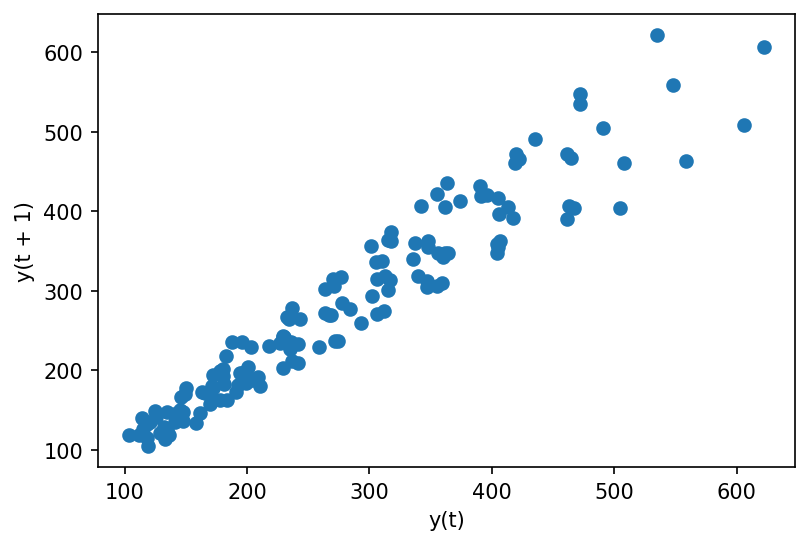

In [104]:
from pandas.plotting import lag_plot

lag_plot(df1['Milhares de passageiros']);

O gráfico acima indica forte correlação entre a série original e a série com atraso 1.

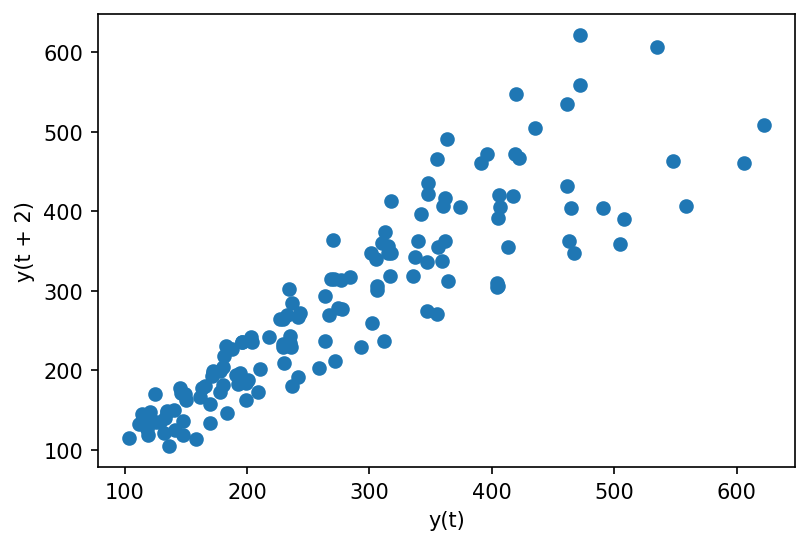

In [105]:
from pandas.plotting import lag_plot

lag_plot(df1['Milhares de passageiros'],lag=2);

## Representação gráfica da autocorrelação



In [106]:
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf

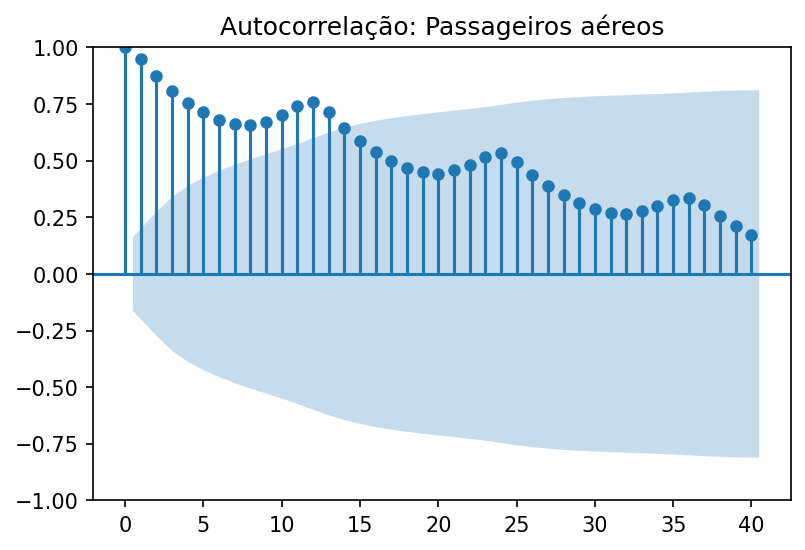

In [107]:
title = 'Autocorrelação: Passageiros aéreos'
lags = 40
plot_acf(df1['Milhares de passageiros'],title=title,lags=lags);


Observe o efeito da sazonalidade e portanto da não-estacionariedade no gráfico da autocorrelação.

A região em azul representa um intervalo de confiança para a correlação, e quando um ponto ultrapassa essa região temos um indicativo de significância da correlação observada.


# Modelos ARIMA (p,d,q)

**Componentes de um modelo ARIMA:**

- **AR (p)**: Componentes autorregressivas, utilizam a relação de dependência entre a observação corrente e as observações em um período prévio.


- **Integrado (d)**: Diferenças para tornar a série estacionária.


- **MA (q)**: Componentes de médias móveis, utilizam a dependência entre uma obervação e um erro residual de um modelo de média móvel aplicado a observações em atraso.



**SARIMA: ARIMA com componentes sazonais.**



Abordagem de Box e Jenkins (1976): Ajustar modelos autorregressivos integrados de médias móveis, ARIMA(p,d,q) a um conjunto de dados. Veja também Box et al. (1994).

Uma estratégia para a construção do modelo será baseada em um ciclo iterativo, na qual a escolha da estrutura do modelo é baseada nos próprios dados:


1. Uma classe geral de modelos é considerada para a análise, no caso modelos ARIMA (***especificação***),


2. Há ***identificação*** do modelo, com base na análise de autocorrelações, autocorrelações parciais e outros critérios,


3. ***Estimação*** dos parâmetros do modelo identificado,


4. ***Verificação*** ou ***diagnóstico*** do modelo ajustado, por meio de uma análise de resíduos, para saber se esse modelo é adequado para fazer previsão, por exemplo.


Se o modelo não for adequado, as estapas 2, 3 e 4 se repetem até obter um ajuste satisfatório. A etapa mais trabalhosa é a identificação.

No contexto desse curso, utilizaremos a função auto_arima do pacote pmdarima do Python para selecionar a ordem do ARIMA.

## Aplicações

In [108]:
!pip show statsmodels
!pip show pmdarima

Name: statsmodels
Version: 0.13.5
Summary: Statistical computations and models for Python
Home-page: https://www.statsmodels.org/
Author: 
Author-email: 
License: BSD License
Location: /home/cibele/.local/lib/python3.10/site-packages
Requires: numpy, packaging, pandas, patsy, scipy
Required-by: category-encoders, plotly-express, pmdarima, pycaret, pynm, ydata-profiling
Name: pmdarima
Version: 2.0.3
Summary: Python's forecast::auto.arima equivalent
Home-page: http://alkaline-ml.com/pmdarima
Author: 
Author-email: 
License: MIT
Location: /home/cibele/.local/lib/python3.10/site-packages
Requires: Cython, joblib, numpy, pandas, scikit-learn, scipy, setuptools, statsmodels, urllib3
Required-by: pycaret, tbats


# Modelos ARIMA, SARIMA. Diagnóstico.


por **Cibele Russo**

Baseado em

- MORETTIN, P. A.; TOLOI, C. M. C.. Análise de séries temporais: modelos lineares univariados. 3. ed. São Paulo: Blucher, 2018.

- EHLERS, R.S. Análise de Séries Temporais. ICMC USP. 2009.


Implementações:

- BROWNLEE, J. Introduction to time series forecasting with python: how to prepare data and develop models to predict the future. Machine Learning Mastery, 2017.

Leituras adicionais:

- HYNDMAN, R. J., ATHANASOPOULOS, G.; Forecasting: principle and practice: O Texts; 2nd edition. 2018. Acesso em 09/07/2022.

- https://otexts.com/fpp2/non-seasonal-arima.html
- https://otexts.com/fpp2/seasonal-arima.html



**Operadores mais usados para séries temporais**

Sejam

- $\tilde{Z}_t = Z_t -\mu$


- $B^m Z_t = Z_{t-m}$ (Operador translação (defasagem, backshift))


- $F^m Z_t = Z_{t+m}$ (Operador translação para o futuro (forward))


- $\Delta = (1-B)$ (Operador diferença)


- $S Z_t = (1-B)^{-1}Z_t = \Delta^{-1}Z_t$ (Operador soma)






## Modelos autorregressivos - AR(p)

$$\tilde{Z}_{t} = \phi_{1}\tilde{Z}_{t-1} + \phi_{2}\tilde{Z}_{t-2} + \ldots + \phi_{p}\tilde{Z}_{t-p} + a_{t}$$

onde $a_{t}$ é um ruído branco.

Sendo o operador autorregressivo estacionário de ordem p dado por

$$\phi(B) = 1-\phi_1 B-\phi_2 B^2-\ldots -\phi_p B^p,$$

podemos reescrever o modelo AR(p) como

$$\phi(B)\tilde{Z}_{t} =  a_{t}$$


## Modelos de médias móveis - MA(q)

$$\tilde{Z}_{t} =  a_t  -  \theta_{1}a_{t-1} -\ldots - \theta_q a_{t-q}$$

$$\tilde{Z}_{t} = (1-\theta_1 B - \ldots -\theta_q B^q) a_t $$

Assim

$$\tilde{Z}_{t}=\theta(B) a_t$$

onde $\theta(B) = 1-\theta_1 B-\ldots-\theta_q B^q$ é o operador de médias móveis de ordem $q$.


## Modelos ARMA(p,q)

Os modelos ARMA(p,q) são dados na forma

$$\tilde{Z}_{t} = \phi_{1}\tilde{Z}_{t-1} + \ldots + \phi_{p}\tilde{Z}_{t-p} +  a_t  -  \theta_{1}a_{t-1} -\ldots - \theta_q a_{t-q}$$

ou podemos reescrever

$$\phi(B)\tilde{Z}_{t} = \theta(B) a_t$$

em que

- $\phi(B)$ é o operador autorregressivo

- $\theta(B)$ é o operador de médias móveis


# Modelos ARIMA (p,d,q)


**Componentes de um modelo ARIMA (p,d,q):**

- **AR (p)**: Componentes autorregressivas, utilizam a relação de dependência entre a observação corrente e as observações em um período prévio

- **Integrado (d)**: Diferenças para tornar a série estacionária

- **MA (q)**: Componentes de médias móveis, utilizam a dependência entre uma obervação e um erro residual de um modelo de média móvel aplicado a observações em atraso.





Considere que $Z_t$ não é estacionária mas

$$W_t = \Delta^d Z_t$$

é uma série estacionária e utilizamos portanto um modelo ARMA(p,q) para $W_t$, ou seja,

$$\phi(B) W_t = \theta(B) a_t.$$

Se $W_t$ for uma diferença de $Z_t$, então dizemos que $Z_t$ segue um modelo autorregressivo _integrado_ de médias móveis, ou um modelo ARIMA:

$$\phi(B) \Delta^d Z_t = \theta(B) a_t$$

de ordem (p,d,q) e escrevemos ARIMA (p,d,q) em que $p$ e $q$ são as ordens de $\phi(B)$ e $\theta(B)$, respectivamente.



# Modelos SARIMA (p,d,q)x(P, D,Q)m

- **SARIMA: ARIMA com sazonalidade**


- Componente sazonal se repete a cada $m$ observações ($m>1$).


- Com dados mensais e $m=12$, tipicamente espera-se que $Z_t$ dependa de $Z_{t-12}$ e talvez $Z_{t-24}$ além de $Z_{t-1}, Z_{t-2}$, ...


- Tomar a primeira diferença $\Delta Z_t = Z_t -Z_{t-1}$ não é suficiente para tornar a
série (aproximadamente) estacionária.


- Considere as diferenças sazonais
$$\Delta_m Z_t = (1 - B^m )Z_t = Z_t - Z_{t-m}$$
sendo $m$ o periodo da sazonalidade.


- A D-ésima diferença sazonal é denotada por $\Delta^D_m$.


- Combinando-se diferenciação simples e sazonais obtem-se o operador $\Delta^d\Delta^D_m$.


**Componentes de um modelo SARIMA (p,d,q)x(P,D,Q)m:**

- $(p,d,q)$: componentes não-sazonais
- $(P,D,Q)_m$: componentes sazonais

Aqui $m$ é o período da sazonalidade.


$$\phi(B) \Phi(B^m ) W_t = \theta(B) \Theta(B^m ) a_ t$$

onde

- $\phi(B) = (1-\alpha_1 B-\ldots \alpha_p B^p)$

- $\Phi(B^m)= (1- \phi_1 B^m-\ldots - \phi_p B^{P_m})$

- $W_t = \Delta^d \Delta^D Z_t = (1-B)^d (1-B^m)^D Z_t$

- $\theta(B) = (1+\beta_1 B + \ldots + \beta_q B^q)$

- $\Theta(B^m) = (1+\theta_1 B^m+\ldots+\theta_Q B^{Q_m})$






**Exemplo:** Série mensal com 1 diferença simples e 1 sazonal com período 12


$\begin{array}{lll}
\Delta \Delta_{12} Z_t & =& (1-B)(1-B^{12})Z_t\\
&=& (1-B-B^{12}+B^{13}) Z_t\\
&=& Z_t-Z_{t-1}-Z_{t-12}+Z_{t-13}\end{array}$


**Exemplo:** Modelo $\text{ SARIMA(1,0,0)}\times(0,1,1)_{12}$


$\begin{array}{rll}
(1-\phi B)(1-B^{12})Z_t &=& (1-\theta B^{12})a_t\\
Z_t &=& Z_{t-12}+\phi(Z_{t-1}-Z_{t-13})+a_t-\theta a_{t-12}\end{array}$



**Observações**

- Na prática os valores de d e D em geral não serão muito maiores do que 1 e um número pequeno de coeficientes será suficiente.

-  Especificar os valores de d e D que tornam a série (aproximadamente) estacionária e remove a maior parte da sazonalidade.

-  Os valores de p, P, q e Q devem ser especificados com base nas funções de autocorrelação e autocorrelação parcial da série diferenciada.

-  Os valores de P e Q são especificados basicamente olhando-se para as defasagens $k = m, 2m, \ldots.$

## Aplicação

<Axes: >

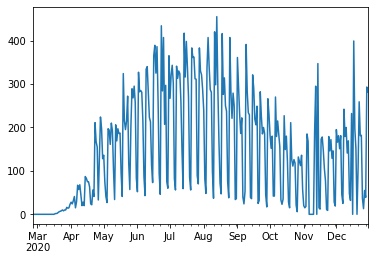

In [109]:
import pandas as pd
import numpy as np
%matplotlib inline

from statsmodels.tsa.statespace.sarimax import SARIMAX

from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from pmdarima import auto_arima

# Ignorar warnings não prejudiciais
import warnings
warnings.filterwarnings("ignore")

np.random.seed(0)

covidSP = pd.read_csv('https://raw.githubusercontent.com/cibelerusso/Aprendizado-Dinamico/main/Data/covidSP.csv', index_col='date', parse_dates=True)

idx = pd.date_range(start=covidSP.index.min(), end=covidSP.index.max(), freq='D')
covidSP = covidSP.reindex(idx)
covidSP.fillna(0,inplace=True)

covidSP['deaths'].plot()

In [110]:
covidSP.index.max()


Timestamp('2020-12-30 00:00:00')

Vamos considerar a decomposição em sazonalidade e tendência em um modelo aditivo, nesse caso porque temos muitos zeros.

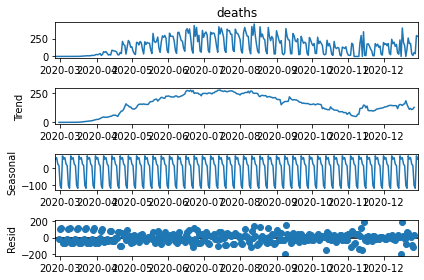

In [111]:
result = seasonal_decompose(covidSP['deaths'], model='additive')
result.plot();

Há sazonalidade nos dados, devido à sistemática de notificações

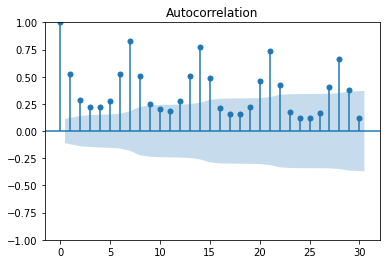

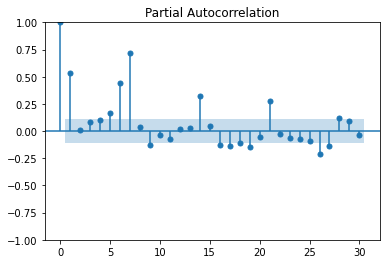

In [112]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf # para determinar (p,q)

# Correlograma

plot_acf(covidSP['deaths'], lags=30)
plot_pacf(covidSP['deaths'], lags=30)
plt.show()

In [113]:
# Ajuste de modelo SARIMA (p,d,q) x (P, D, Q)m

auto_arima(covidSP['deaths'],seasonal=True,m=7).summary()


stepwise_fit = auto_arima(covidSP['deaths'], start_p=0, start_q=0,
                          max_p=6, max_q=3, m=7,
                          seasonal=True,
                          trace=True,
                          error_action='ignore',
                          suppress_warnings=True,
                          stepwise=True)

stepwise_fit.summary()

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(1,0,1)[7] intercept   : AIC=3579.716, Time=0.39 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=3825.903, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=3563.494, Time=0.30 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=3581.821, Time=0.18 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=3823.921, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[7] intercept   : AIC=3808.539, Time=0.09 sec
 ARIMA(1,1,0)(2,0,0)[7] intercept   : AIC=3519.108, Time=0.53 sec
 ARIMA(1,1,0)(2,0,1)[7] intercept   : AIC=3488.255, Time=0.84 sec
 ARIMA(1,1,0)(1,0,1)[7] intercept   : AIC=3486.546, Time=0.44 sec
 ARIMA(1,1,0)(0,0,1)[7] intercept   : AIC=3683.983, Time=0.16 sec
 ARIMA(1,1,0)(1,0,2)[7] intercept   : AIC=3488.166, Time=0.74 sec
 ARIMA(1,1,0)(0,0,2)[7] intercept   : AIC=3635.827, Time=0.28 sec
 ARIMA(1,1,0)(2,0,2)[7] intercept   : AIC=inf, Time=0.87 sec
 ARIMA(2,1,0)(1,0,1)[7] intercept   : AIC=3454.120, Time=0.80 sec
 ARIMA(2,1,0)(0,0,1)[7] intercept   : 

<class 'statsmodels.iolib.summary.Summary'>
"""
                                       SARIMAX Results                                        
==============================================================================================
Dep. Variable:                                      y   No. Observations:                  309
Model:             SARIMAX(6, 1, 0)x(2, 0, [1, 2], 7)   Log Likelihood               -1680.399
Date:                                Mon, 22 Sep 2025   AIC                           3382.797
Time:                                        10:43:57   BIC                           3423.828
Sample:                                    02-26-2020   HQIC                          3399.203
                                         - 12-30-2020                                         
Covariance Type:                                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9592      0.041    -23.251      0.000      -1.040      -0.878
ar.L2         -0.8946      0.072    -12.354      0.000      -1.037      -0.753
ar.L3         -0.7748      0.085     -9.071      0.000      -0.942      -0.607
ar.L4         -0.7301      0.113     -6.486      0.000      -0.951      -0.509
ar.L5         -0.6982      0.102     -6.869      0.000      -0.897      -0.499
ar.L6         -0.5276      0.112     -4.717      0.000      -0.747      -0.308
ar.S.L7        1.2774      0.159      8.055      0.000       0.967       1.588
ar.S.L14      -0.3189      0.148     -2.159      0.031      -0.608      -0.029
ma.S.L7       -1.5033      0.105    -14.319      0.000      -1.709      -1.298
ma.S.L14       0.7067      0.090      7.866      0.000       0.531       0.883
sigma2      3182.0755    174.014     18.286      0.000    2841.014    3523.137
===================================================================================
Ljung-Box (L1) (Q):                   0.07   Jarque-Bera (JB):               399.10
Prob(Q):                              0.79   Prob(JB):                         0.00
Heteroskedasticity (H):               2.69   Skew:                             0.08
Prob(H) (two-sided):                  0.00   Kurtosis:                         8.57
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [114]:
len(covidSP)

309

In [115]:
len(covidSP)*0.9

278.1

In [116]:
treino = covidSP.iloc[:278]
teste = covidSP.iloc[278:]

In [147]:
modelo = SARIMAX(treino['deaths'],order=(6,1,0),seasonal_order=(2,0,2,7))
resultado = modelo.fit()
resultado.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                       SARIMAX Results                                        
==============================================================================================
Dep. Variable:                                 deaths   No. Observations:                  278
Model:             SARIMAX(6, 1, 0)x(2, 0, [1, 2], 7)   Log Likelihood               -1494.299
Date:                                Mon, 22 Sep 2025   AIC                           3010.598
Time:                                        10:46:42   BIC                           3050.463
Sample:                                    02-26-2020   HQIC                          3026.593
                                         - 11-29-2020                                         
Covariance Type:                                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9345      0.040    -23.123      0.000      -1.014      -0.855
ar.L2         -0.8817      0.064    -13.867      0.000      -1.006      -0.757
ar.L3         -0.7919      0.074    -10.713      0.000      -0.937      -0.647
ar.L4         -0.7567      0.095     -7.976      0.000      -0.943      -0.571
ar.L5         -0.7456      0.087     -8.523      0.000      -0.917      -0.574
ar.L6         -0.5873      0.094     -6.254      0.000      -0.771      -0.403
ar.S.L7        1.2677      0.146      8.687      0.000       0.982       1.554
ar.S.L14      -0.3191      0.135     -2.365      0.018      -0.584      -0.055
ma.S.L7       -1.5835      0.097    -16.292      0.000      -1.774      -1.393
ma.S.L14       0.7759      0.091      8.557      0.000       0.598       0.954
sigma2      2705.3683    148.174     18.258      0.000    2414.953    2995.783
===================================================================================
Ljung-Box (L1) (Q):                   0.54   Jarque-Bera (JB):               601.60
Prob(Q):                              0.46   Prob(JB):                         0.00
Heteroskedasticity (H):               2.65   Skew:                             0.27
Prob(H) (two-sided):                  0.00   Kurtosis:                        10.20
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [148]:
resultado.fittedvalues

2020-02-26      0.000000
2020-02-27      0.000000
2020-02-28      0.000000
2020-02-29      0.000000
2020-03-01      0.000000
                 ...    
2020-11-25    143.723635
2020-11-26    142.302135
2020-11-27     93.241165
2020-11-28     85.027066
2020-11-29     35.630340
Freq: D, Length: 278, dtype: float64

In [149]:
# Obtain predicted values
inicio=len(treino)
fim=len(treino)+len(teste)-1
previsões = resultado.predict(start=inicio, end=fim, dynamic=False).rename('Previsões SARIMA(6,1,0)(2,0,2,7) ')
previsões.index = teste.index


In [150]:
previsões

2020-11-30     41.633759
2020-12-01     98.176747
2020-12-02    147.933044
2020-12-03    180.939625
2020-12-04     91.508089
2020-12-05    116.187437
2020-12-06     40.354081
2020-12-07     46.475006
2020-12-08     91.648111
2020-12-09    155.978804
2020-12-10    198.957045
2020-12-11     77.494531
2020-12-12    126.933596
2020-12-13     45.527364
2020-12-14     50.330837
2020-12-15    104.713498
2020-12-16    166.030319
2020-12-17    212.162431
2020-12-18     78.712542
2020-12-19    143.478913
2020-12-20     51.673893
2020-12-21     58.025726
2020-12-22    120.872325
2020-12-23    175.636036
2020-12-24    220.554561
2020-12-25     87.576129
2020-12-26    157.670923
2020-12-27     60.227179
2020-12-28     68.851038
2020-12-29    135.684974
2020-12-30    184.013026
Freq: D, Name: Previsões SARIMA(6,1,0)(2,0,2,7) , dtype: float64

Passar <tt> dynamic = False </tt> significa que as previsões em cada ponto são geradas usando o histórico completo até aquele ponto (todos os valores defasados).

Passar <tt> typ = 'levels' </tt> prevê os níveis das variáveis endógenas originais. Se tivéssemos usado o padrão <tt> typ = 'linear' </tt>, teríamos visto previsões lineares em termos de variáveis endógenas diferenciadas.

Para obter mais informações sobre esses argumentos, visite https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima_model.ARIMAResults.predict.html

In [151]:
for i in range(len(previsões)):
    print(f"predicted={previsões[i]:<11.10}, expected={teste['deaths'][i]}")

predicted=41.63375851, expected=19.0
predicted=98.17674696, expected=195.0
predicted=147.9330437, expected=166.0
predicted=180.939625 , expected=181.0
predicted=91.50808923, expected=151.0
predicted=116.1874367, expected=181.0
predicted=40.35408089, expected=46.0
predicted=46.47500643, expected=25.0
predicted=91.64811109, expected=242.0
predicted=155.9788042, expected=179.0
predicted=198.9570446, expected=200.0
predicted=77.49453089, expected=141.0
predicted=126.9335955, expected=169.0
predicted=45.52736432, expected=47.0
predicted=50.33083722, expected=32.0
predicted=104.7134978, expected=232.0
predicted=166.0303188, expected=0.0
predicted=212.1624314, expected=399.0
predicted=78.71254225, expected=197.0
predicted=143.4789129, expected=151.0
predicted=51.67389319, expected=0.0
predicted=58.02572574, expected=107.0
predicted=120.8723249, expected=259.0
predicted=175.636036 , expected=181.0
predicted=220.554561 , expected=182.0
predicted=87.57612872, expected=37.0
predicted=157.6709233,

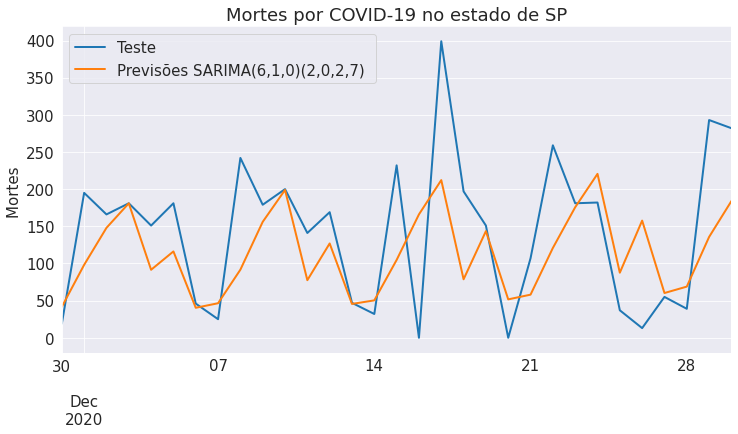

In [152]:
# Plot predictions against known values
title = 'Mortes por COVID-19 no estado de SP'
ylabel='Mortes '
xlabel=''

ax = teste['deaths'].plot(legend=True,figsize=(12,6),title=title, label='Teste')
previsões.plot(legend=True)

ax.autoscale(axis='x',tight=True)
ax.set(xlabel=xlabel, ylabel=ylabel);

<Axes: >

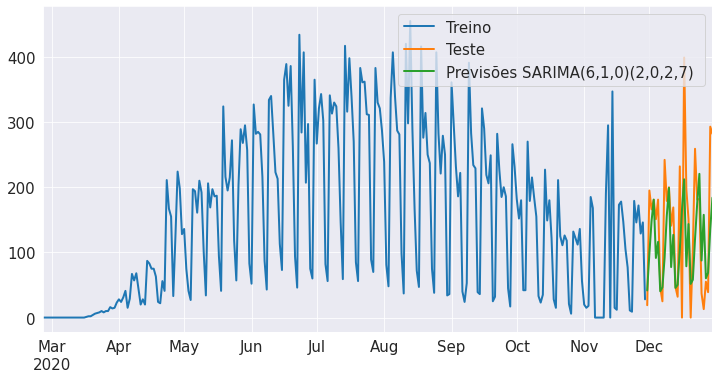

In [153]:
treino['deaths'].plot(legend=True, label='Treino')
teste['deaths'].plot(legend=True, label='Teste')
previsões.plot(legend=True, figsize=(12,6))

### Previsões para dados cujos tempos ainda não estão nas bases

In [154]:
# Notem o uso de "trend", vejam o help para outras variações = Aqui tem mais uma possibilidade para buscar o melhor ajuste.


modelo = SARIMAX(covidSP['deaths'],order=(6,1,0),seasonal_order=(2,0,1,7), trend='c')
resultados = modelo.fit()
fcast = resultados.predict(len(covidSP),len(covidSP)+14).rename('Previsões SARIMA(6,1,0)(2,0,2,7)')

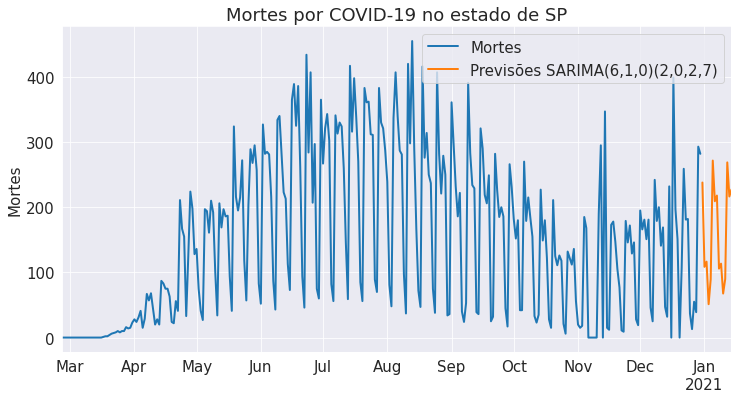

In [155]:
title = 'Mortes por COVID-19 no estado de SP'
ylabel='Mortes'
xlabel=''

ax = covidSP['deaths'].plot(legend=True,figsize=(12,6),title=title, label='Mortes')
fcast.plot(legend=True)
ax.autoscale(axis='x',tight=True)
ax.set(xlabel=xlabel, ylabel=ylabel);

## Diagnóstico em modelos SARIMA

### Métricas

In [156]:
from sklearn.metrics import mean_squared_error

error = mean_squared_error(teste['deaths'], previsões)
print(f'EQM SARIMA(6,1,0)(2,0,2,7): {error:11.10}')

EQM SARIMA(6,1,0)(2,0,2,7):  7253.78247


In [157]:
from statsmodels.tools.eval_measures import rmse

error = rmse(teste['deaths'], previsões)
print(f'REQM SARIMA(6,1,0)(2,0,2,7): {error:11.10}')

REQM SARIMA(6,1,0)(2,0,2,7): 85.16914036


### Análise de resíduos

Considere inicialmente um modelo ARIMA

$\phi(B) W_t = \theta(B) a_t$ com $W_t = \Delta^d Z_t$ supondo que $a_t$ é um ruído branco.

Se o modelo for verdadeiro, então os erros verdadeiros $a_t = \theta^{-1}(B) \phi(B) W_t$ devem ser um ruído branco.

Uma análise equivalente poderia ser feita para modelos mais gerais SARIMA.

Quando o modelo é estimado, ou seja, quando são obtidos $\widehat{\theta}$ e $\widehat{\phi}$, as quantidades

$$\widehat{a}_t = \widehat{\theta}^{-1}(B) \widehat{\phi}(B) W_t$$

são chamadas de **resíduos**. Se o modelo for correto, eles devem ser aproximadamente não correlacionados.

Uma forma de analisar os resíduos ajustados é simplesmente considerar

$$r_t = Z_t - \widehat{Z}_t$$

e podemos analisar a distribuição, estatísticas descritivas, a autocorrelação dos resíduos e verificar se existe algum padrão nos mesmos.

Leitura adicional: https://otexts.com/fpp2/residuals.html

In [158]:
# Uma forma de obter os resíduos pelo ajuste do modelo

resíduos = resultados.resid

In [159]:
resíduos.describe()

count    309.000000
mean      -0.284218
std       57.283791
min     -293.184972
25%      -27.144647
50%       -2.501689
75%       25.408263
max      301.577063
dtype: float64

{'whiskers': [<matplotlib.lines.Line2D at 0x7734cc376890>,
 'caps': [<matplotlib.lines.Line2D at 0x7734cc376e30>,
 'boxes': [<matplotlib.lines.Line2D at 0x7734cc376590>],
 'medians': [<matplotlib.lines.Line2D at 0x7734cc377430>],
 'fliers': [<matplotlib.lines.Line2D at 0x7734cc377730>],
 'means': []}

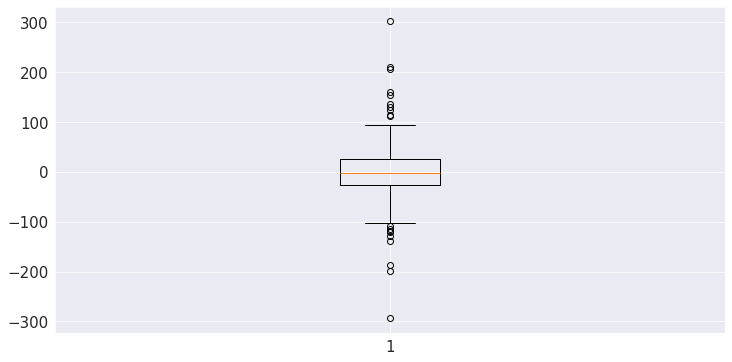

In [160]:
plt.boxplot(resíduos)

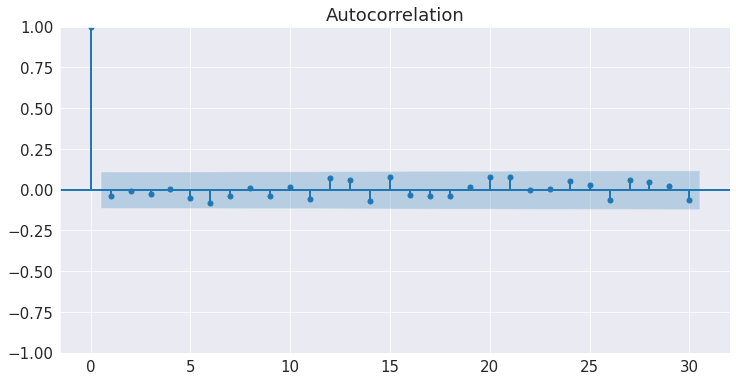

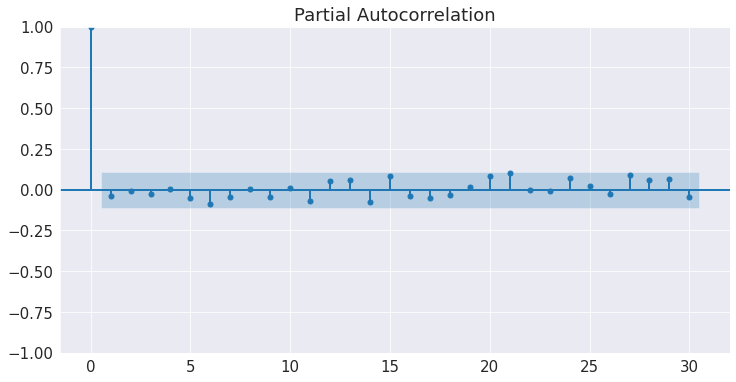

In [161]:
plot_acf(resíduos, lags=30)
plot_pacf(resíduos, lags=30)
plt.show()

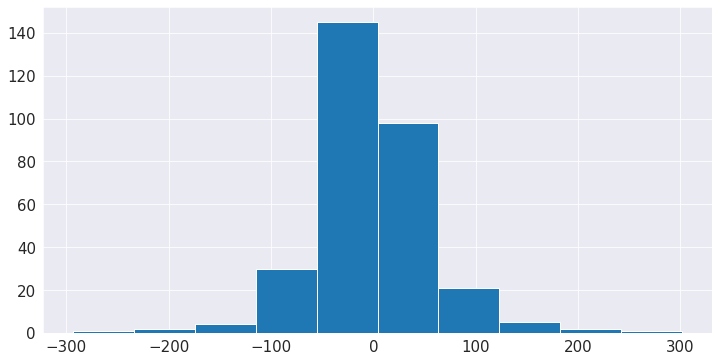

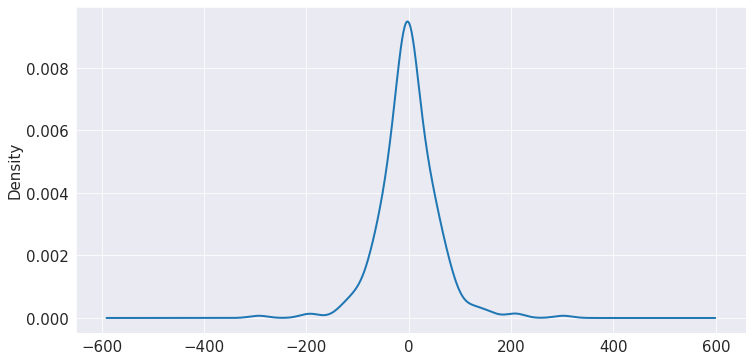

In [162]:
from matplotlib import pyplot


resíduos.hist()

pyplot.show()
resíduos.plot(kind='kde')
pyplot.show()

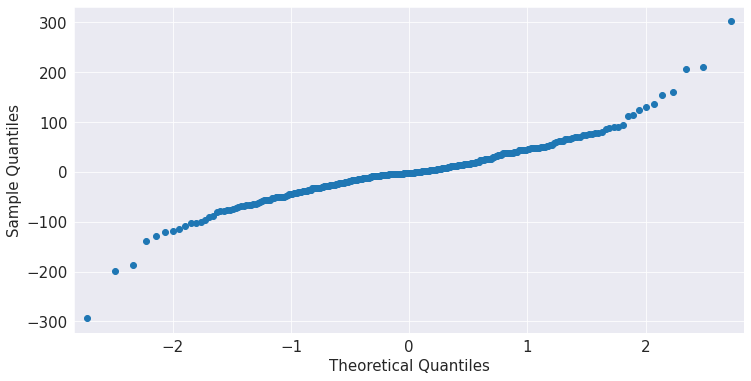

In [163]:
from statsmodels.graphics.gofplots import qqplot

qqplot(resíduos)
pyplot.show()

**Exercício: O que aconteceria com os resíduos se um modelo incorreto tivesse sido ajustado?**

# Previsão de séries temporais: Método Theta e expansões

por **Cibele Russo**




Baseado em

- ASSIMAKOPOULOS, V., NIKOLOPOULOS, K. The theta model: a decomposition approach to forecasting. International Journal of Forecasting, v. 16, n. 4, p. 521-530, 2000.

Implementações:

https://www.statsmodels.org/devel/examples/notebooks/generated/theta-model.html

Leituras adicionais:

- FIORUCCI, J. A., PELLEGRINI, T. R., LOUZADA, F., PETROPOULOS, F., & KOEHLER, A. B. (2016). Models for optimising the theta method and their relationship to state space models. International Journal of Forecasting, 32(4), 1151-1161. Disponível em https://www.sciencedirect.com/science/article/pii/S0169207016300243. Acessado em 07/08/2022.


- FIORUCCI, J. A. (2016). Time series forecasting:advances on Theta method. Tese de doutorado. Disponível em https://repositorio.ufscar.br/bitstream/handle/ufscar/7399/TeseJAF.pdf?sequence=1&isAllowed=y. Acessado em 07/08/2022.

- PELLEGRINI, T. R. Uma avaliação de métodos de previsão aplicados à grandes quantidades de séries temporais univariadas. Dissertação de mestrado. Universidade Federal de São Carlos. 2012. Disponível em https://repositorio.ufscar.br/bitstream/handle/ufscar/4563/4757.pdf?sequence=1&isAllowed=y. Acessado em 07/08/2022.

- HYNDMAN, R. J., KOEHLER, A. B., SNYDER, R. D., \& GROSE, S. (2002). A state space framework for automatic forecasting using exponential smoothing methods. International Journal of Forecasting, 18(3), 439-454.

- HYNDMAN, R. J., & BILLAH, B. (2003). Unmasking the Theta method. International Journal of Forecasting, 19(2), 287-290.




## Método Theta

- O método Theta é simples e preciso para se fazer previsão (forecasting) em séries temporais.


- Premiado na Competição M3 de forecasting https://en.wikipedia.org/wiki/Makridakis_Competitions


- Suposição: A série é não-sazonal ou dessazonalizada


- Tem relação com o método de Suavização exponencial simples (SES)


**Resumo do Metodo Theta**


1. O método decompõe a série temporal original em duas novas linhas através dos chamados coeficientes Theta, que são aplicados à segunda diferença dos dados. O processo de decomposição tem a vantagem de explorar informações nos dados que geralmente não são capturados e modelados completamente através da extrapolação da série temporal original.


2. As chamadas Linhas-Theta podem ser consideradas como novas séries temporais e são extrapoladas separadamente usando um método de previsão apropriado.


3. Concluída a extrapolação de cada Linha Theta, a recomposição ocorre por meio de um esquema de combinação, a fim de calcular as previsões pontuais da série temporal original.


4. A combinação das Linhas Theta é considerada para a previsão.




Os passos do algoritmo para a implementação (PELLEGRINI, 2012) são


1. **Teste de Sazonalidade**: Teste cada série temporal para verificar a existência de comportamento sazonal via teste para a função de autocorrelação, com lag de um ano para séries anuais, lag de 12 meses para séries mensais e lag de 4 meses para séries trimestrais e assim por diante.  

    De uma forma geral, a série é considerada sazonal se
    
    $$|r_m| > q_{1-a/2}\sqrt{\displaystyle\frac{1+2\sum_{i=1}^{m-1}r_i^2}{n}}$$
    
    em que $r_k$ é a função e autocorrelação de lag $k$, $m$ é o número de períodos do ciclo sazonal (por exemplo, 12 meses em uma sazonalidade anual), $n$ é o tamanho amostral, $q$ é o quantil da distribuição normal e $(1-a/2)$ é o nível de confiança do teste. Se a série for identificada como sazonal, é necessário fazer uma decomposição para eliminar a sazonalidade.  


2. **Dessazonalização**: Dessazonalize as séries temporais identificadas no passo 1 através do método de decomposição clássica (multiplicativo).


3. **Decomposição**: Cada série temporal é decomposta em duas linhas-Theta, $Z_t(0)$ e $Z_t(2)$.


4. **Extrapolação**: $Z_t(0)$ e $Z_t(2)$ são extrapoladas respectivamente através do modelo de regressão linear e do modelo de alisamento exponencial simples.


5. **Combinação**: As previsões produzidas por $\widehat{Z}_{t+h}(0)$ e $\widehat{Z}_{t+h}(2)$ são combinadas a partir da média aritmética.


6. **Resazonalização**: As previsões do passo anterior são resazonalizadas resultando nas previsões finais.


## O Método Theta


O método Theta é baseado no conceito de modificação das curvaturas locais da série temporal.   Esta  mudança  é  obtida  a  partir  de  um  coeficiente,  denominado  coeficiente Theta,  denotado  pela  letra  grega  $\theta$.


Originalmente, ASSIMAKOPOULOS & NIKOLOPOULOS (2000) propuseram a Linha Theta como a solução da equação

$$\Delta^2 Z_t(\theta) = \theta \Delta^2 Y_t, t=3,\ldots,n$$


em que

$Y_1,\ldots, Y_n$ é a série original (não sazonal ou dessazonalizada) e $\Delta$ é o operador diferença

$$\Delta Z_t = Z_t - Z_{t-1}.$$

Os valores iniciais de $Z_1$ e $Z_2$ são obtidos minimizando

$$\sum_{t=1}^{n} [Y_t - Z_t(\theta)]^2$$

Entretanto, uma solução analítica para calcular $Z(\theta)$ é dada por

$$Z_t(\theta) = \theta Y_t + (1-\theta)(A_n + B_n t), \ t=1,\ldots, n$$

em que $A_n$ e $B_n$ são coeficientes de mínimos quadrados de um modelo de regressão linear de $Y_1,\ldots, Y_n$ contra $1,\ldots,n$ (as expressões são dadas em FIORUCCI (2016)).

## Generalizações para o Método Theta

- Existem algumas propostas de generalização do Método Theta na literatura

- Modelos para otimizar o Método Theta são apresentados por FIORUCCI et. al (2016)

### Modelo Theta Otimizado

- Algumas adaptações são feitas e o modelo é reescrito como um modelo de espaço de estado (FIORUCCI et. al, 2016)

$\begin{array}{lll}
Y_t &=& \mu_t + \epsilon_t,\\
\mu_t &= & {{l}}_{t-1} + \left(1-\displaystyle{\frac{1}{\theta}}\right) \left\{(1-\alpha)^{t-1} A_n + \left[\displaystyle\frac{1-(1-\alpha)^t}{\alpha}\right] B_n\right\},\\
{l}_t &=& \alpha Y_t + (1-\alpha){l}_{t-1}
\end{array}$

com parâmetros ${l}_0 \in \mathbb{R}$, $\alpha\in(0,1)$ e $\theta\in[1,\infty]$.




A previsão pra $h$ passos à frente com origem em n é dada por

$\begin{array}{lll}\widehat{Y}_{n+h|n} &=& E[Y_{n+h}|Y_1,\ldots,Y_n]\\
&=&{l}_n + \left(\displaystyle 1-\frac{1}{\theta}\right)\times \\
&& \left\{(1-\alpha)^n A_n + \left[(h-1)+\displaystyle\frac{1-(1-\alpha)^{n+1}}{\alpha}\right] B_n\right\}\end{array}$

Além disso, é possível obter um intervalo de predição com nível de confiança de $(1-a)\%$

$\widehat{Y}_{n+h|n} \pm q_{1-a/2}\sqrt{[1+(h-1)\alpha^2]\sigma^2}$.

Se $\theta = 2$ é possível mostrar que este método produz as mesmas previsões do método usual.

## Aplicação do Método Theta em Python

In [164]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.rc("figure",figsize=(12,6))
plt.rc("font",size=15)
plt.rc("lines",linewidth=2)
sns.set_style("darkgrid")

In [165]:
from statsmodels.tsa.forecasting.theta import ThetaModel
tm = ThetaModel(dados_treino['deaths'])
res = tm.fit()
print(res.summary())

                              ThetaModel Results                              
Dep. Variable:                 deaths   No. Observations:                  103
Method:                       OLS/SES   Deseasonalized:                   True
Date:                Mon, 22 Sep 2025   Deseas. Method:         Multiplicative
Time:                        10:46:45   Period:                              7
Sample:                    05-01-2020                                         
                         - 08-11-2020                                         
  Parameter Estimates   
          Parameters    
------------------------
b0    1.0849620352761489
alpha 0.2136755942953248
------------------------


In [166]:
len(dados_treino)

103

In [167]:
res = ThetaModel(dados_treino['deaths']).fit()
fcast = res.forecast(21)




In [168]:
fcast

2020-08-12    313.554543
2020-08-13    313.947018
2020-08-14    295.935115
2020-08-15    270.507362
2020-08-16    104.705229
2020-08-17     56.368381
2020-08-18    357.643019
2020-08-19    318.449922
2020-08-20    318.837617
2020-08-21    300.534892
2020-08-22    274.702595
2020-08-23    106.325487
2020-08-24     57.238728
2020-08-25    363.152995
2020-08-26    323.345302
2020-08-27    323.728216
2020-08-28    305.134669
2020-08-29    278.897828
2020-08-30    107.945746
2020-08-31     58.109075
2020-09-01    368.662971
Freq: D, Name: forecast, dtype: float64

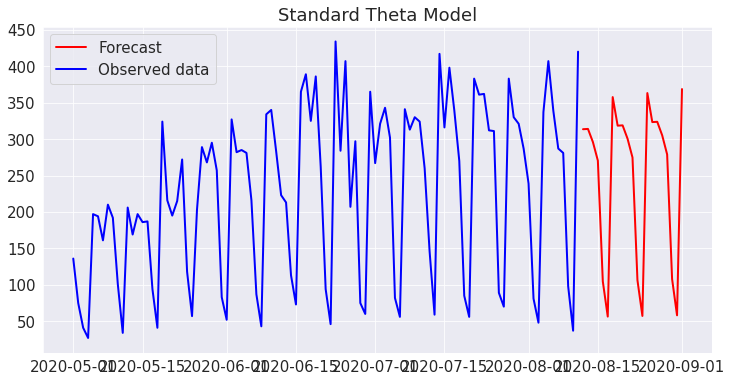

In [169]:
plt.figure(figsize = (12,6))

plt.plot(fcast,  color = 'red', label = 'Forecast')
plt.plot(dados_treino['deaths'],color = 'blue', label = 'Observed data')

plt.title('Standard Theta Model')
plt.legend()
plt.show()

In [170]:
tm = ThetaModel(dados_treino['deaths'], method="multiplicative")
res = tm.fit(use_mle=True)
print(res.summary())

                              ThetaModel Results                              
Dep. Variable:                 deaths   No. Observations:                  103
Method:                           MLE   Deseasonalized:                   True
Date:                Mon, 22 Sep 2025   Deseas. Method:               Additive
Time:                        10:46:46   Period:                              7
Sample:                    05-01-2020                                         
                         - 08-11-2020                                         
   Parameter Estimates   
           Parameters    
-------------------------
b0     1.3308370293260108
alpha 0.12575833400949465
-------------------------


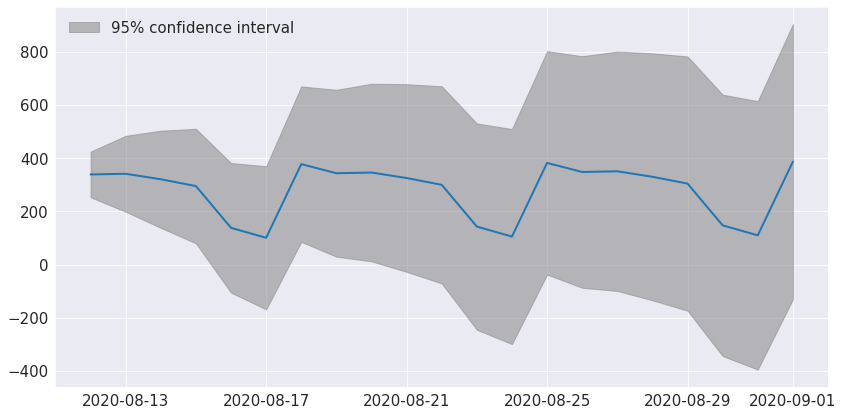

In [171]:
ax = res.plot_predict(21, theta=2)


**Exercício:** Calcule as métricas como erro quadrático médio, erro absoluto médio e raiz do erro quadrático médio para as previsões pontuais pelo método Theta.

### Comparação de todos os modelos para a previsão de dados de COVID-19

In [172]:
import numpy as np
import pandas as pd
from statsmodels.tsa.api import SimpleExpSmoothing, Holt, ExponentialSmoothing
from pmdarima import auto_arima

# Função para calcular métricas de erro
def calcular_metricas(y_real, y_prev):
    rmse = np.sqrt(np.mean((y_real - y_prev)**2))
    mae = np.mean(np.abs(y_real - y_prev))
    return rmse, mae

# Dados de treino e teste
y_treino = dados_treino['deaths']
y_teste = dados_teste['deaths']

# 1. Modelo Holt
modelo_holt = Holt(y_treino).fit()
prev_holt = modelo_holt.forecast(len(y_teste))

# 2. Modelo Holt-Winters
modelo_hw = ExponentialSmoothing(y_treino, trend='add', seasonal='add', seasonal_periods=7).fit()
prev_hw = modelo_hw.forecast(len(y_teste))

# 3. Modelo ARIMA (auto_arima para seleção de parâmetros)
modelo_arima = auto_arima(y_treino, seasonal=True, m=7, trace=False, suppress_warnings=True)
prev_arima = modelo_arima.predict(n_periods=len(y_teste))

# 4. Modelo Theta
modelo_theta = ThetaModel(y_treino, method="multiplicative")  # `h` é o horizonte de previsão; ajusta-se dinamicamente ao comprimento de teste
res = tm.fit(use_mle=True)  # O modelo Theta espera uma DataFrame com coluna 'y'
prev_theta = res.forecast(len(y_teste))




In [173]:
# Calcular métricas para cada modelo
metricas = pd.DataFrame({
    'Modelo': ['Holt', 'Holt-Winters', 'ARIMA', 'Theta'],
    'RMSE': [
        calcular_metricas(y_teste, prev_holt)[0],
        calcular_metricas(y_teste, prev_hw)[0],
        calcular_metricas(y_teste, prev_arima)[0],
        calcular_metricas(y_teste, prev_theta)[0]
    ],
    'MAE': [
        calcular_metricas(y_teste, prev_holt)[1],
        calcular_metricas(y_teste, prev_hw)[1],
        calcular_metricas(y_teste, prev_arima)[1],
        calcular_metricas(y_teste, prev_theta)[1]
    ]
})

print(metricas)

         Modelo        RMSE         MAE
0          Holt  129.208846  108.244186
1  Holt-Winters   56.811327   45.945781
2         ARIMA   73.646760   62.412288
3         Theta   72.845328   65.933981


In [174]:
dados_treino.index

DatetimeIndex(['2020-05-01', '2020-05-02', '2020-05-03', '2020-05-04',
               '2020-05-05', '2020-05-06', '2020-05-07', '2020-05-08',
               '2020-05-09', '2020-05-10',
               ...
               '2020-08-02', '2020-08-03', '2020-08-04', '2020-08-05',
               '2020-08-06', '2020-08-07', '2020-08-08', '2020-08-09',
               '2020-08-10', '2020-08-11'],
              dtype='datetime64[ns]', length=103, freq='D')

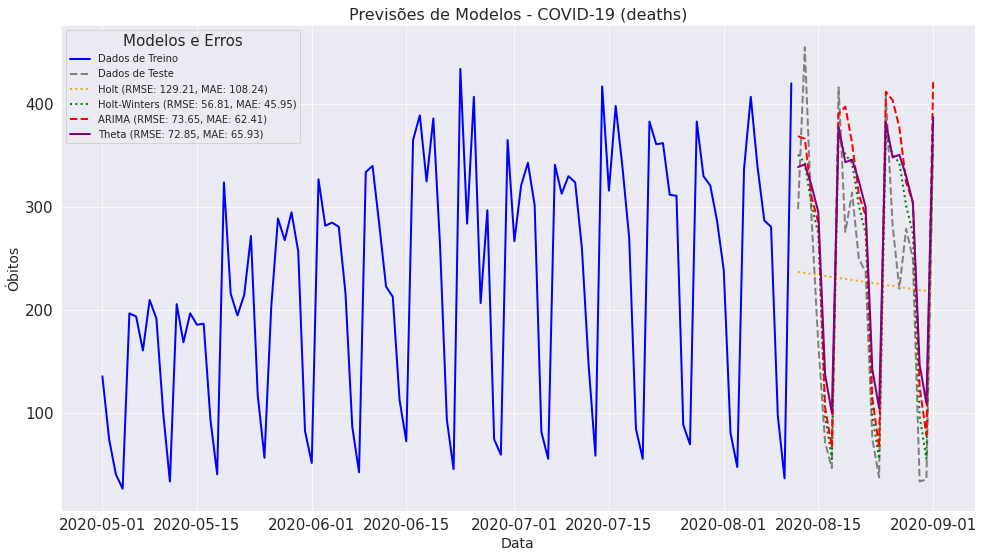

In [175]:
import matplotlib.pyplot as plt

# Criar o gráfico
plt.figure(figsize=(14, 8))

# Plotar os dados de treino
plt.plot(dados_treino.index, y_treino, label='Dados de Treino', color='blue', linewidth=2)

# Plotar os dados de teste
plt.plot(y_teste.index, y_teste, label='Dados de Teste', color='gray', linestyle='dashed', linewidth=2)

# Adicionar previsões de cada modelo
plt.plot(y_teste.index, prev_holt, label=f'Holt (RMSE: {metricas.loc[0, "RMSE"]:.2f}, MAE: {metricas.loc[0, "MAE"]:.2f})', color='orange', linestyle='dotted', linewidth=2)
plt.plot(y_teste.index, prev_hw, label=f'Holt-Winters (RMSE: {metricas.loc[1, "RMSE"]:.2f}, MAE: {metricas.loc[1, "MAE"]:.2f})', color='green', linestyle='dotted', linewidth=2)
plt.plot(y_teste.index, prev_arima, label=f'ARIMA (RMSE: {metricas.loc[2, "RMSE"]:.2f}, MAE: {metricas.loc[2, "MAE"]:.2f})', color='red', linestyle='--', linewidth=2)
plt.plot(y_teste.index, prev_theta, label=f'Theta (RMSE: {metricas.loc[3, "RMSE"]:.2f}, MAE: {metricas.loc[3, "MAE"]:.2f})', color='purple', linestyle='-', linewidth=2)

# Configurações do gráfico
plt.title('Previsões de Modelos - COVID-19 (deaths)', fontsize=16)
plt.xlabel('Data', fontsize=14)
plt.ylabel('Óbitos', fontsize=14)
plt.legend(loc='upper left', fontsize=10, title='Modelos e Erros')
#plt.grid(True, linestyle='-', alpha=0.5)
plt.tight_layout()

# Mostrar o gráfico
plt.show()


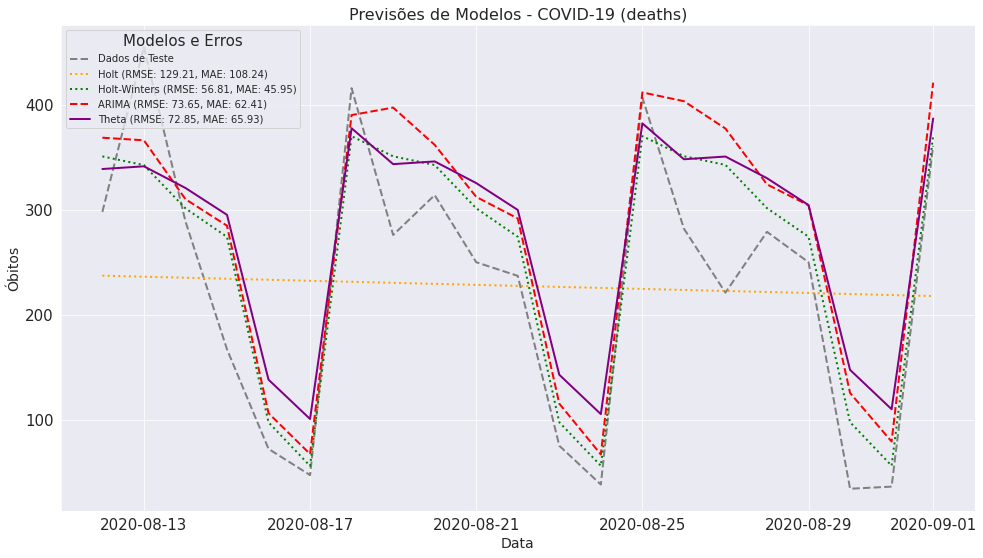

In [176]:
import matplotlib.pyplot as plt

# Criar o gráfico
plt.figure(figsize=(14, 8))

# Plotar os dados de treino
#plt.plot(dados_treino.index, y_treino, label='Dados de Treino', color='blue', linewidth=2)

# Plotar os dados de teste
plt.plot(y_teste.index, y_teste, label='Dados de Teste', color='gray', linestyle='dashed', linewidth=2)

# Adicionar previsões de cada modelo
plt.plot(y_teste.index, prev_holt, label=f'Holt (RMSE: {metricas.loc[0, "RMSE"]:.2f}, MAE: {metricas.loc[0, "MAE"]:.2f})', color='orange', linestyle='dotted', linewidth=2)
plt.plot(y_teste.index, prev_hw, label=f'Holt-Winters (RMSE: {metricas.loc[1, "RMSE"]:.2f}, MAE: {metricas.loc[1, "MAE"]:.2f})', color='green', linestyle='dotted', linewidth=2)
plt.plot(y_teste.index, prev_arima, label=f'ARIMA (RMSE: {metricas.loc[2, "RMSE"]:.2f}, MAE: {metricas.loc[2, "MAE"]:.2f})', color='red', linestyle='--', linewidth=2)
plt.plot(y_teste.index, prev_theta, label=f'Theta (RMSE: {metricas.loc[3, "RMSE"]:.2f}, MAE: {metricas.loc[3, "MAE"]:.2f})', color='purple', linestyle='-', linewidth=2)

# Configurações do gráfico
plt.title('Previsões de Modelos - COVID-19 (deaths)', fontsize=16)
plt.xlabel('Data', fontsize=14)
plt.ylabel('Óbitos', fontsize=14)
plt.legend(loc='upper left', fontsize=10, title='Modelos e Erros')
#plt.grid(True, linestyle='-', alpha=0.5)
plt.tight_layout()

# Mostrar o gráfico
plt.show()
